# Vorlesung 2 Statische Visualisierung

Eure Namen

- 1) Fadi Arabo
- 2) Vorname Nachname
- 3) ...

# Setup

In [39]:
# Installation der benötigten Pakete
%pip install gapminder pandas plotnine seaborn

Note: you may need to restart the kernel to use updated packages.


In [40]:
# Installiere fehlendes Paket bei Bedarf
%pip install "setuptools<82"
# Importiere benötigte Bibliotheken
import pandas as pd
from plotnine import *
from gapminder import gapminder # Datensatz mit Informationen zu Ländern, Kontinenten, Lebenserwartung, Bevölkerung und BIP pro Kopf
import numpy as np
import seaborn as sb

Note: you may need to restart the kernel to use updated packages.


# Gapminder - EDA (Explorative Daten Analyse)

In [41]:
# Zeige die Form des Gapminder-Datensatzes
print(gapminder.shape) #Länge und Breite des Datensatzes

# Zeige die Spaltennamen des Gapminder-Datensatzes
print(gapminder.columns) #Spaltennamen des Datensatzes

# Zeige die ersten Zeilen des Gapminder-Datensatzes
print(gapminder.head()) #die ersten 5 Zeilen des Datensatzes

# Daten für Deutschland filtern
germany_data = gapminder[gapminder['country'] == 'Germany']
print(germany_data.tail()) #die letzten 5 Zeilen des Datensatzes für Deutschland

(1704, 6)
Index(['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap'],
      dtype='str')
       country continent  year  lifeExp       pop   gdpPercap
0  Afghanistan      Asia  1952   28.801   8425333  779.445314
1  Afghanistan      Asia  1957   30.332   9240934  820.853030
2  Afghanistan      Asia  1962   31.997  10267083  853.100710
3  Afghanistan      Asia  1967   34.020  11537966  836.197138
4  Afghanistan      Asia  1972   36.088  13079460  739.981106
     country continent  year  lifeExp       pop    gdpPercap
571  Germany    Europe  1987   74.847  77718298  24639.18566
572  Germany    Europe  1992   76.070  80597764  26505.30317
573  Germany    Europe  1997   77.340  82011073  27788.88416
574  Germany    Europe  2002   78.670  82350671  30035.80198
575  Germany    Europe  2007   79.406  82400996  32170.37442


In [42]:
# Beschreibe die Daten
print(gapminder.describe()) # Beschreibe den Gapminder-Datensatz

# Deutschland Daten beschreiben
print(germany_data.describe()) # Beschreibe den Datensatz für Deutschland

             year      lifeExp           pop      gdpPercap
count  1704.00000  1704.000000  1.704000e+03    1704.000000
mean   1979.50000    59.474439  2.960121e+07    7215.327081
std      17.26533    12.917107  1.061579e+08    9857.454543
min    1952.00000    23.599000  6.001100e+04     241.165876
25%    1965.75000    48.198000  2.793664e+06    1202.060309
50%    1979.50000    60.712500  7.023596e+06    3531.846988
75%    1993.25000    70.845500  1.958522e+07    9325.462346
max    2007.00000    82.603000  1.318683e+09  113523.132900
              year    lifeExp           pop     gdpPercap
count    12.000000  12.000000  1.200000e+01     12.000000
mean   1979.500000  73.444417  7.754704e+07  20556.684433
std      18.027756   3.872603  4.341644e+06   8076.261913
min    1952.000000  67.500000  6.914595e+07   7144.114393
25%    1965.750000  70.675000  7.571112e+07  14284.834935
50%    1979.500000  73.150000  7.824802e+07  21272.226985
75%    1993.250000  76.387500  8.095109e+07  26826.198

In [43]:
# Filter für 1952 und 2007 erstellen
gm_1952 = gapminder[gapminder['year'] == 1952].copy()
gm_2007 = gapminder[gapminder['year'] == 2007].copy()

# Korrelationsmatrizen (nur numerische Variablen) berechnen
corr_1952 = gm_1952[['lifeExp', 'pop', 'gdpPercap']].corr()
corr_2007 = gm_2007[['lifeExp', 'pop', 'gdpPercap']].corr()

# Ausgabe der Korrelationsmatrizen
print("=== Correlation Matrix – 1952 ===")
print(corr_1952.round(3))
print("\n=== Correlation Matrix – 2007 ===")
print(corr_2007.round(3))

=== Correlation Matrix – 1952 ===
           lifeExp    pop  gdpPercap
lifeExp      1.000 -0.003      0.278
pop         -0.003  1.000     -0.025
gdpPercap    0.278 -0.025      1.000

=== Correlation Matrix – 2007 ===
           lifeExp    pop  gdpPercap
lifeExp      1.000  0.048      0.679
pop          0.048  1.000     -0.056
gdpPercap    0.679 -0.056      1.000


In [44]:
#  Datenvorbereitung für Korrelationsmatrix 1952 vs. 2007
gm_1952 = gapminder[gapminder['year'] == 1952][['lifeExp', 'pop', 'gdpPercap']].corr().reset_index().melt(id_vars='index')
gm_1952['year'] = '1952'

gm_2007 = gapminder[gapminder['year'] == 2007][['lifeExp', 'pop', 'gdpPercap']].corr().reset_index().melt(id_vars='index')
gm_2007['year'] = '2007'

# Kombinieren der beiden DataFrames
corr_df = pd.concat([gm_1952, gm_2007])
corr_df.columns = ['var1', 'var2', 'correlation', 'year']

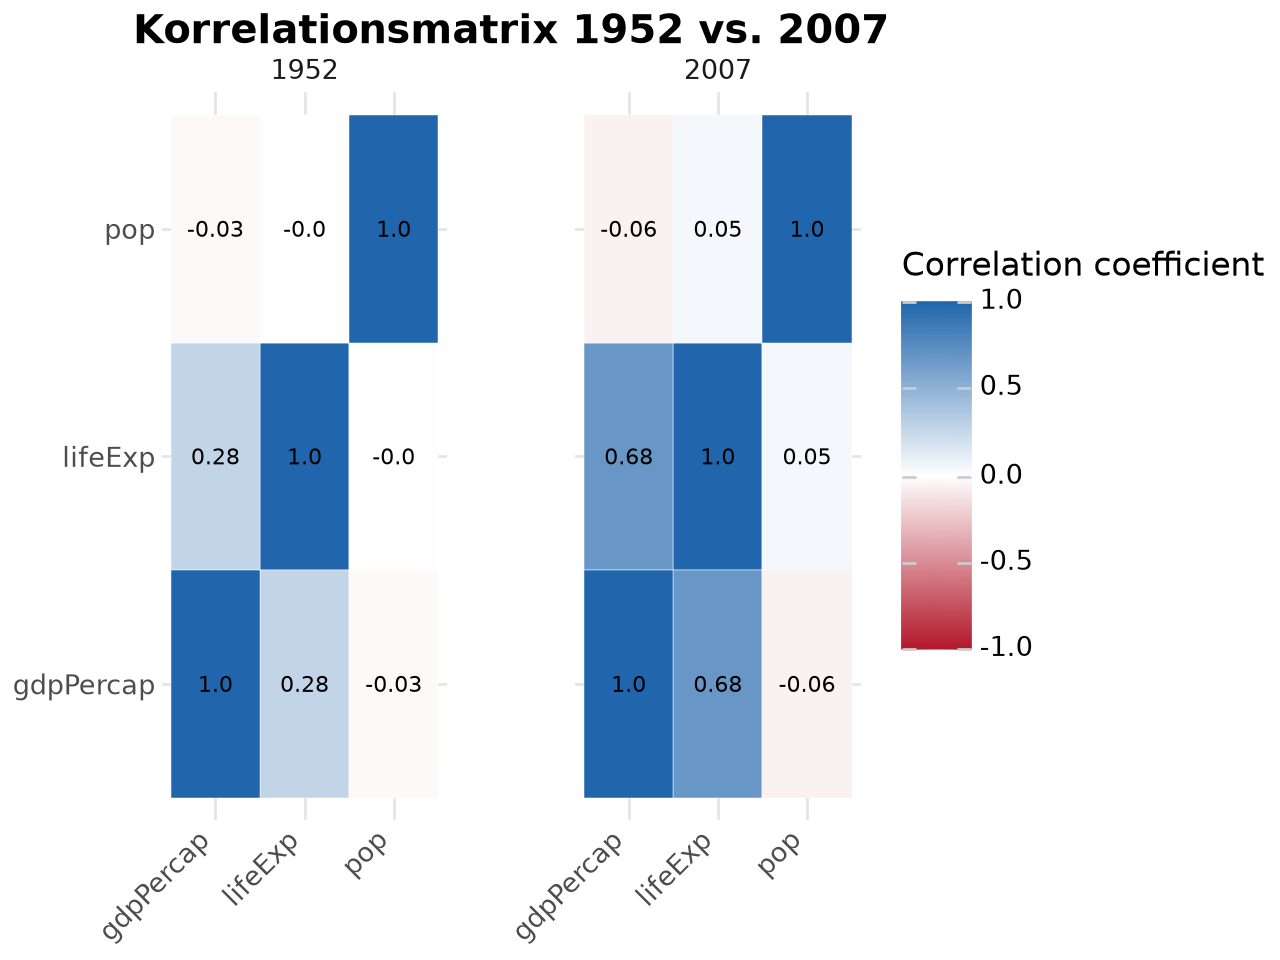

In [45]:
# Korrelationsplot/matrix mit plotnine erstellen
(
    ggplot(corr_df, aes(x='var1', y='var2', fill='correlation')) +
    geom_tile(color='white') +
    facet_wrap('~year') +
    geom_text(aes(label='round(correlation,2)'), color='black', size=8) +
    scale_fill_gradient2(low='#b2182b', mid='white', high='#2166ac', limits=(-1,1)) +
    labs(
        title='Korrelationsmatrix 1952 vs. 2007',
        subtitle='',
        x='', y='', fill='Correlation coefficient'
    ) +
    theme_minimal(base_size=12) +
    theme(
        axis_text_x=element_text(rotation=45, ha='right'),
        panel_spacing_x=0.1,
        plot_title=element_text(weight='bold')
    )
)

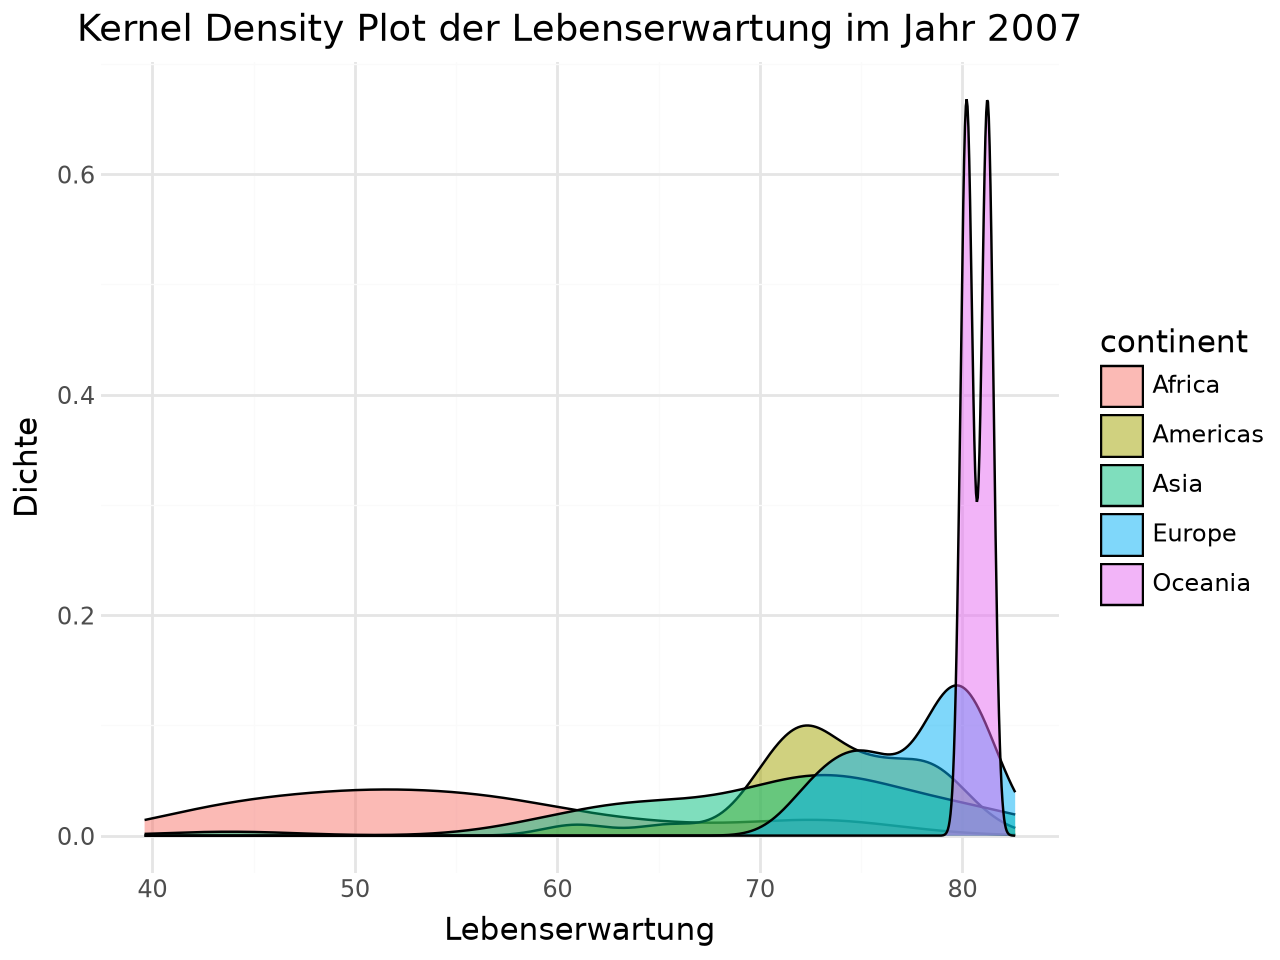

In [46]:
# Kernel density plot 2007 für Lebenserwartung
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='lifeExp', fill='continent')) +
    geom_density(alpha=0.5) +
    labs(title='Kernel Density Plot der Lebenserwartung im Jahr 2007',
         x='Lebenserwartung',
         y='Dichte') +
    theme_minimal()
)

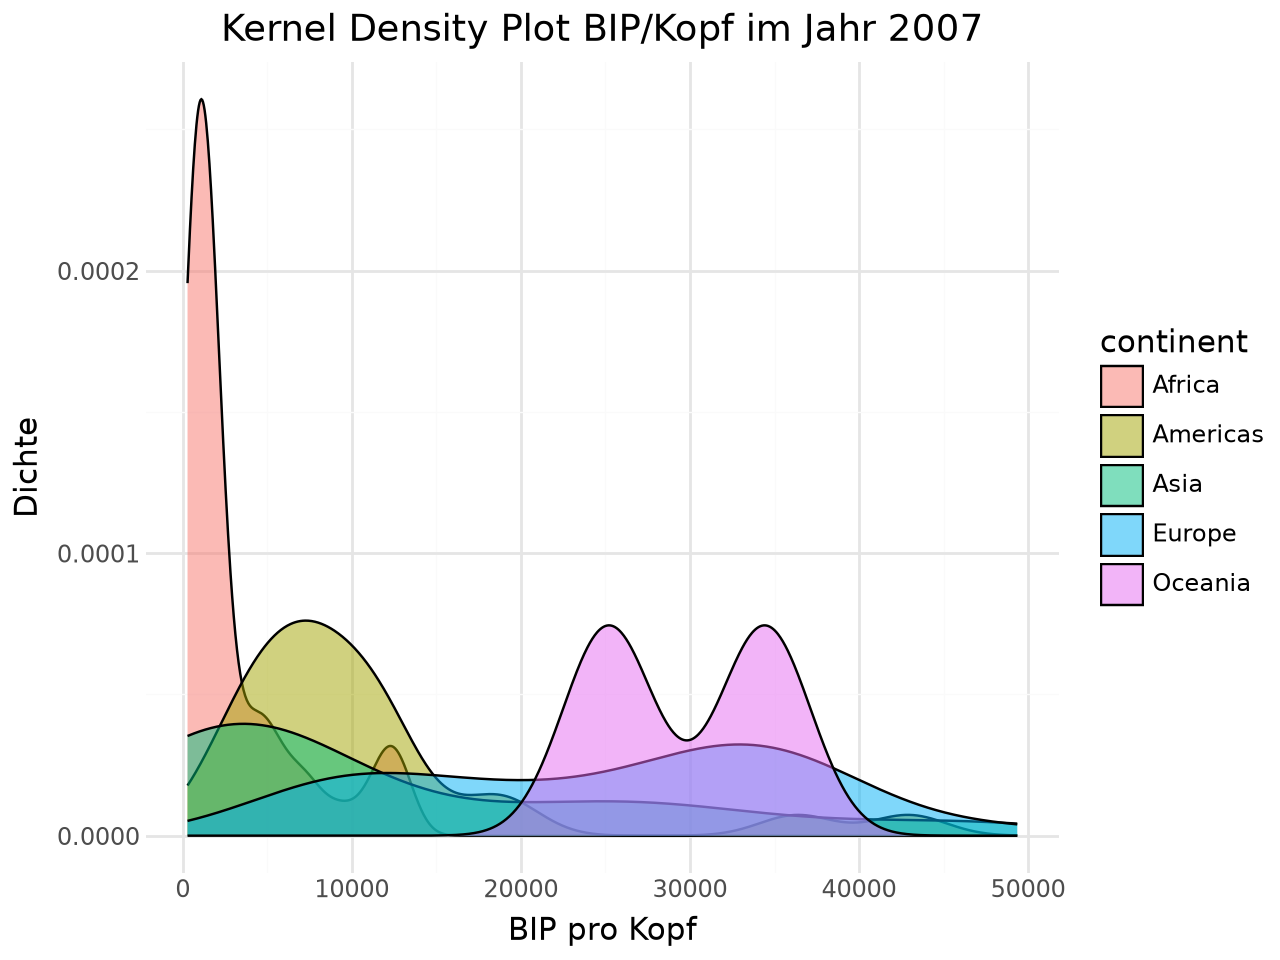

In [47]:
# Kernel density plot 2007 für gdpPercap
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='gdpPercap', fill='continent')) +
    geom_density(alpha=0.5) +
    labs(title='Kernel Density Plot BIP/Kopf im Jahr 2007',
         x='BIP pro Kopf',
         y='Dichte') +
    theme_minimal()
)

f:\Uni\Datenvisualisierung2026\.venv\Lib\site-packages\plotnine\stats\stat_bin.py:112: PlotnineWarning: 'stat_bin()' using 'bins = 8'. Pick better value with 'binwidth'.


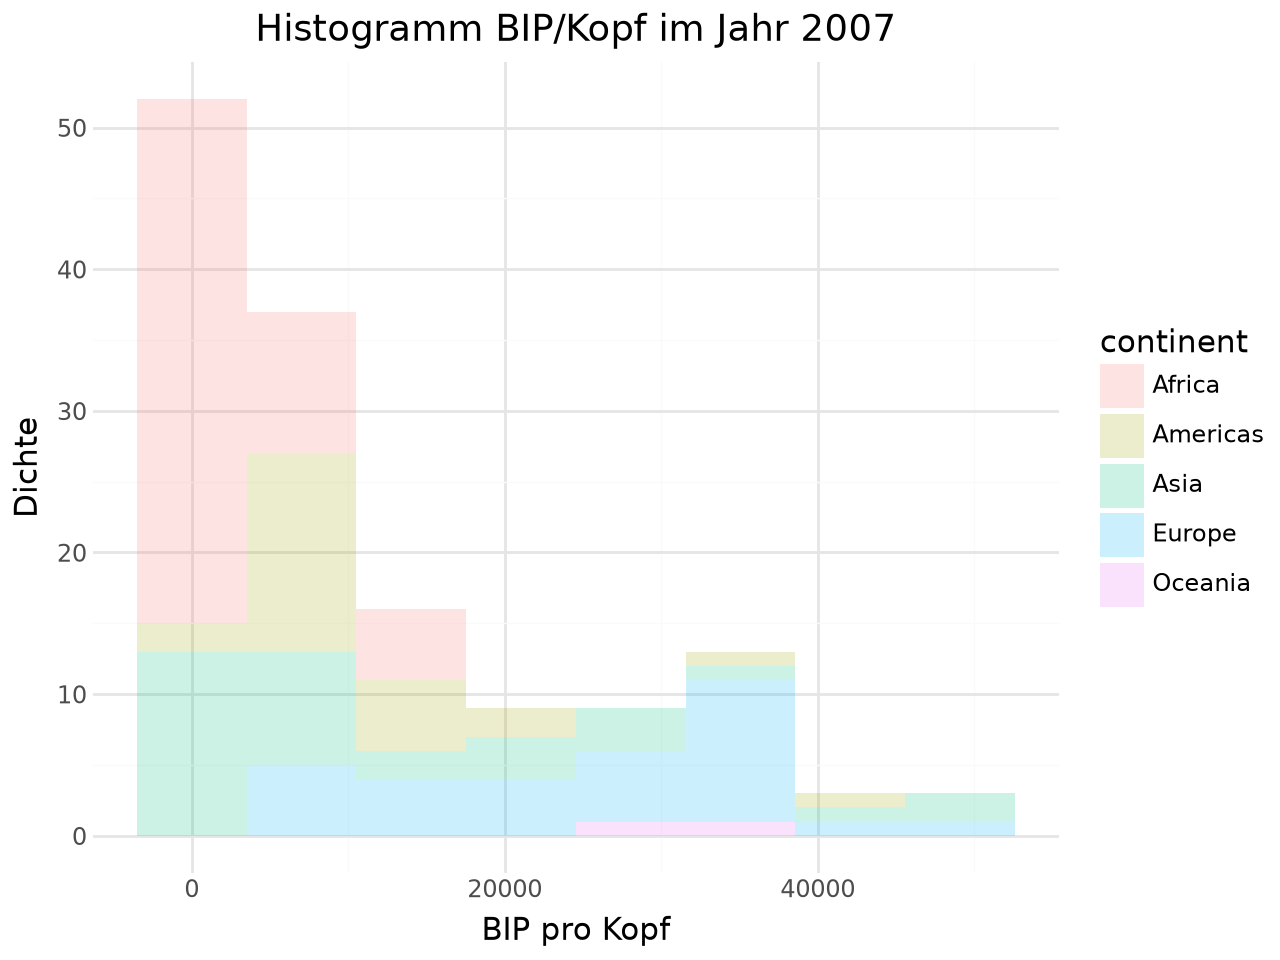

In [48]:
# histogram 2007 für gdpPercap
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='gdpPercap', fill='continent')) +
    geom_histogram(alpha=0.2) +
    labs(title='Histogramm BIP/Kopf im Jahr 2007',
         x='BIP pro Kopf',
         y='Dichte') +
    theme_minimal()
)

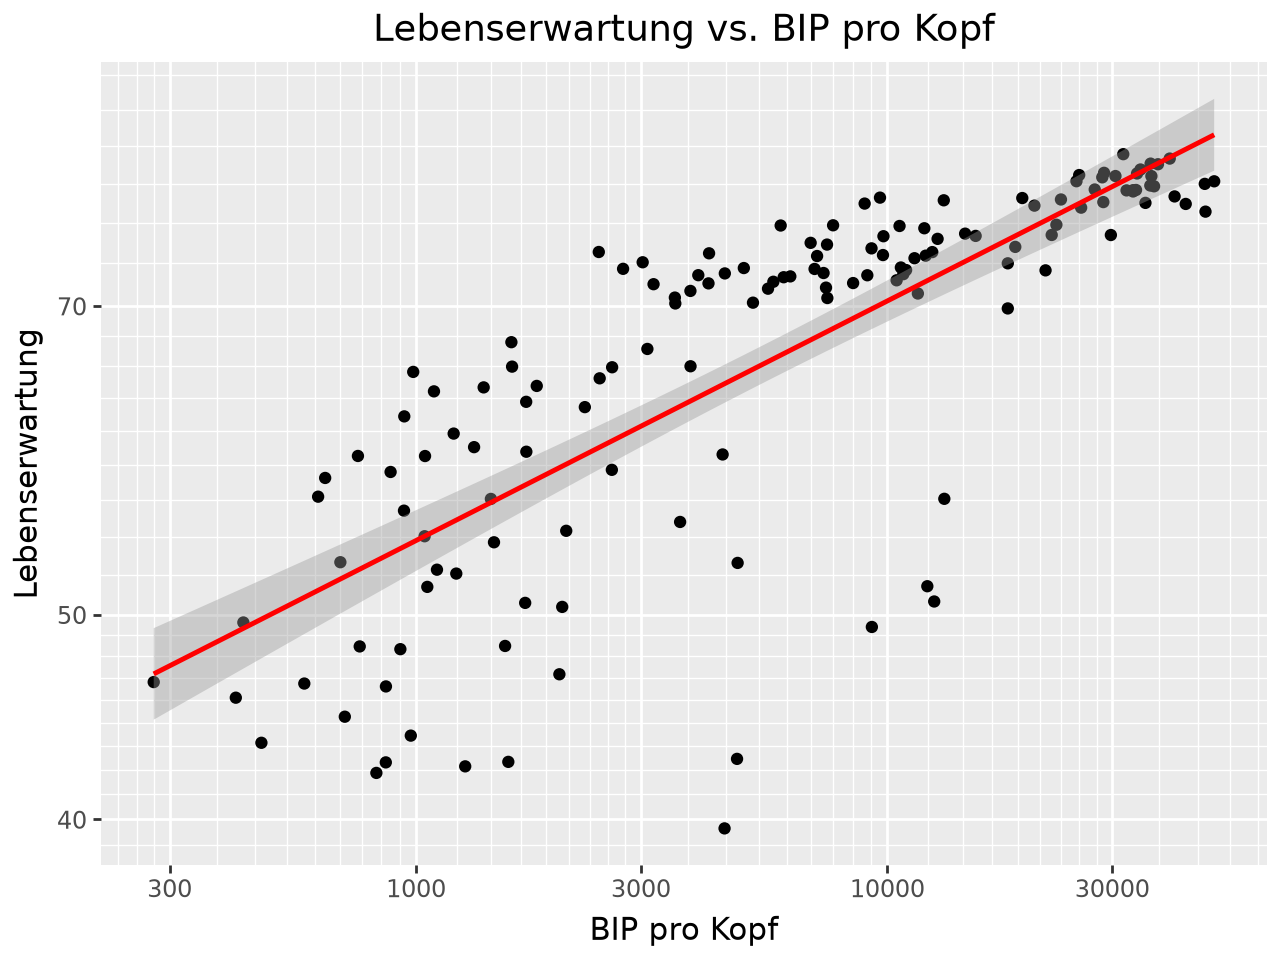

In [49]:
# Scatterplot Lebenserwartung vs. BIP pro Kopf 2007
(ggplot(data_2007, aes(x='gdpPercap', y='lifeExp'))
 + geom_point()
 + geom_smooth(method='lm', color='red')
 + scale_x_log10()
 + scale_y_log10()
 + labs(title='Lebenserwartung vs. BIP pro Kopf',
        x='BIP pro Kopf',
        y='Lebenserwartung')
        )


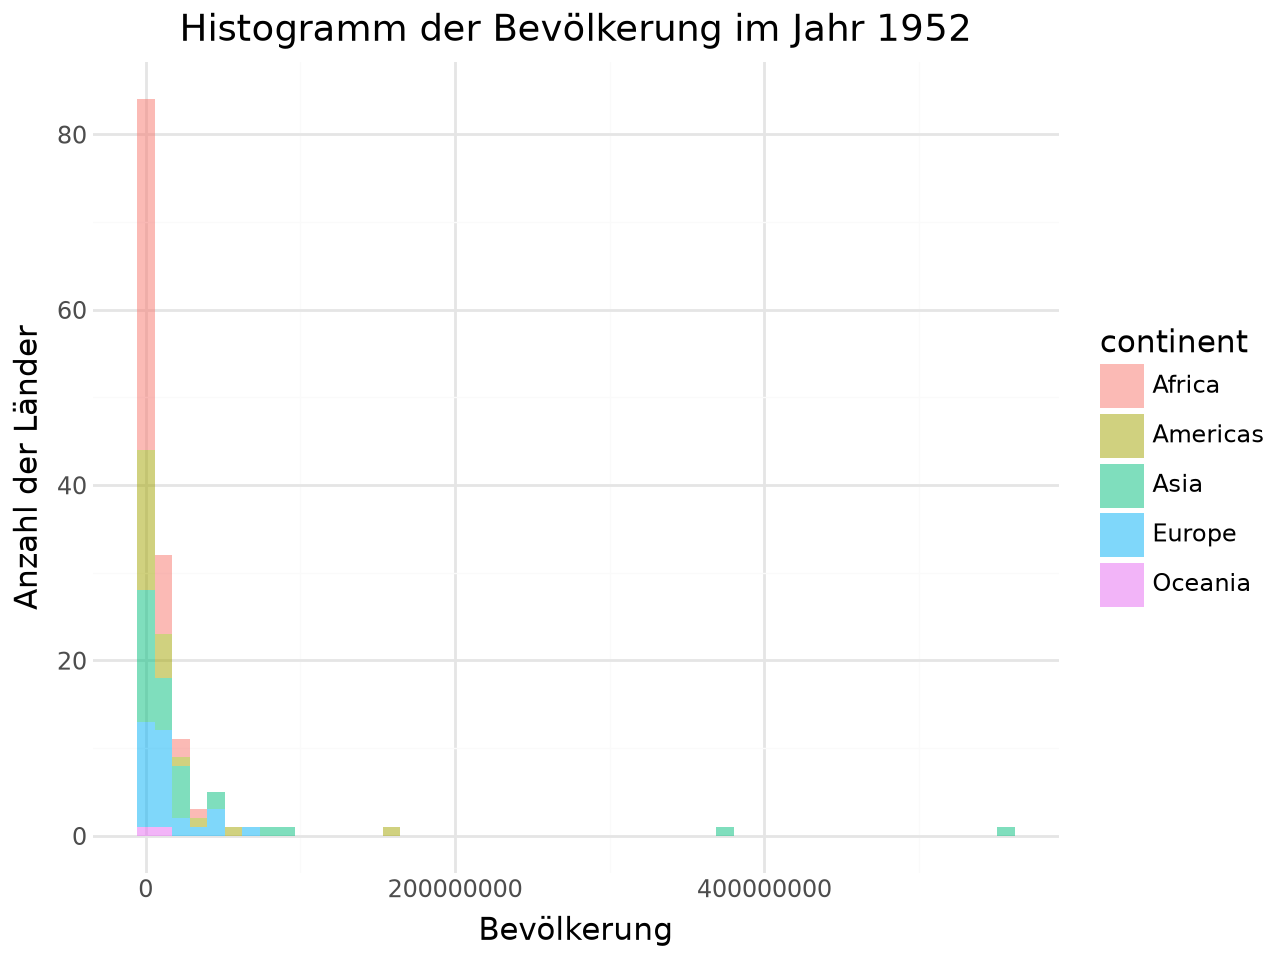

In [50]:
# Histogramm für die Bevölkerung im Jahr 1952
data_1952 = gapminder[gapminder['year'] == 1952]

(
    ggplot(data_1952, aes(x='pop', fill='continent')) +
    geom_histogram(alpha=0.5, bins=50) +
    labs(
        title='Histogramm der Bevölkerung im Jahr 1952',
        x='Bevölkerung',
        y='Anzahl der Länder'
    ) +
    theme_minimal()
)

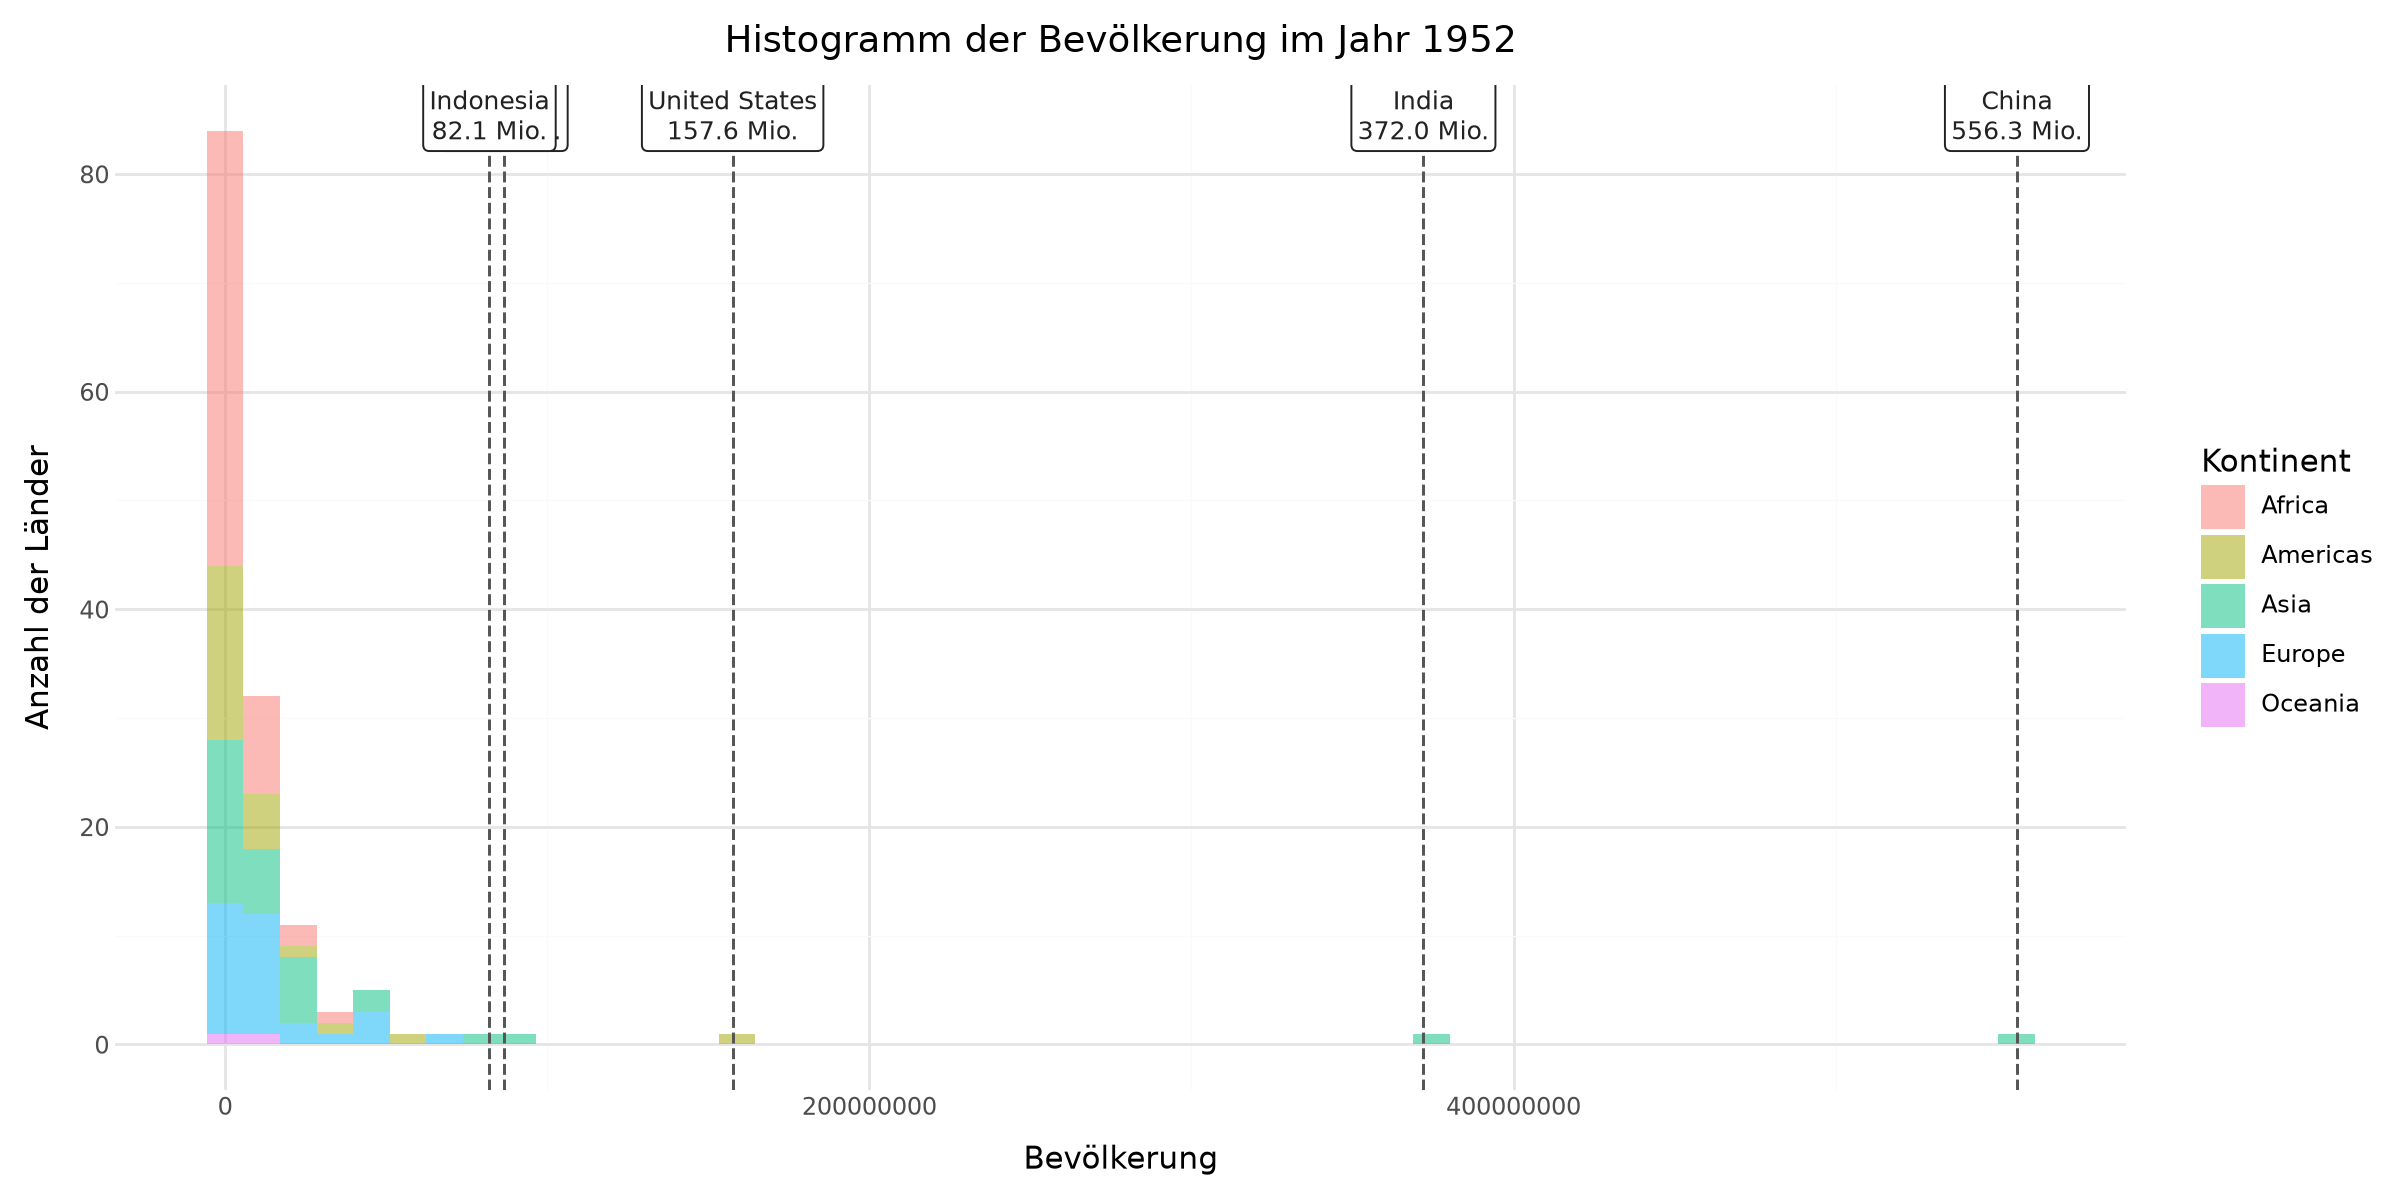

In [51]:
# Imports
from plotnine import (
    ggplot, aes, geom_histogram, geom_vline, geom_label,
    labs, theme_minimal, theme
)

# Bevölkerung im Jahr 1952
data_1952 = gapminder.loc[gapminder["year"] == 1952].copy()

# Fünf bevölkerungsreichste Länder
top_5 = data_1952.nlargest(5, "pop").copy()
top_5["label"] = top_5.apply(
    lambda row: f"{row['country']}\n{row['pop'] / 1e6:.1f} Mio.",
    axis=1,
)

plot = (
    ggplot(data_1952, aes(x="pop", fill="continent"))
    + geom_histogram(alpha=0.5, bins=50)
    + geom_vline(
        data=top_5,
        mapping=aes(xintercept="pop"),
        inherit_aes=False,
        linetype="dashed",
        color="#555555",
        size=0.6,
    )
    + geom_label(
        data=top_5,
        mapping=aes(x="pop", label="label"),
        y=float("inf"),
        inherit_aes=False,
        va="top",
        ha="center",
        size=9,
        fill="white",
        color="#222222",
    )
    + labs(
        title="Histogramm der Bevölkerung im Jahr 1952",
        x="Bevölkerung",
        y="Anzahl der Länder",
        fill="Kontinent",
    )
    + theme_minimal()
    + theme(figure_size=(12, 6))
)

display(plot)

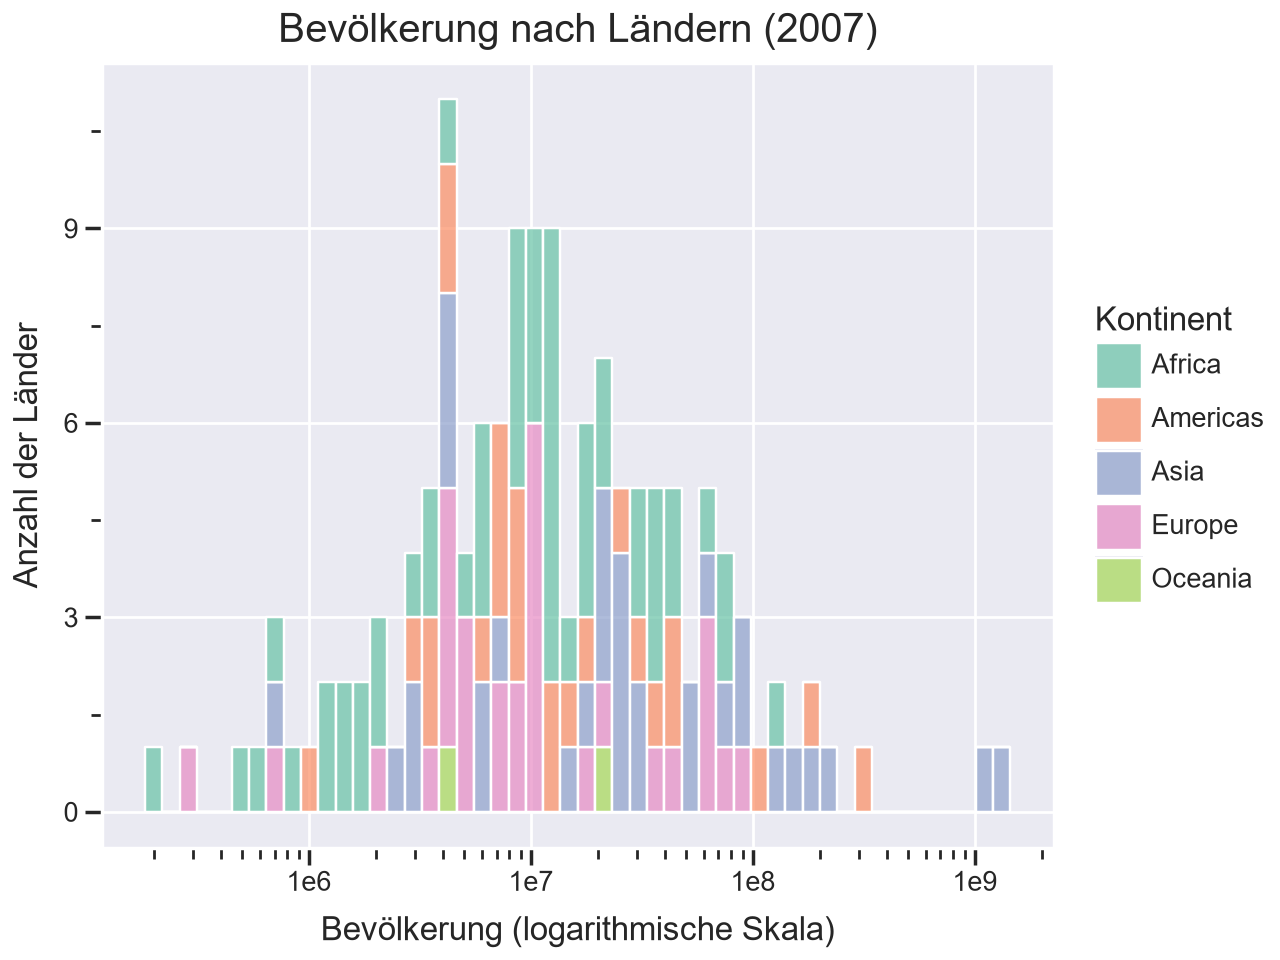

In [52]:
# Histogramm für die Bevölkerung im Jahr 2007 im logarithmischen Maßstab
# in Python Seaborn Style

(
    ggplot(data_2007, aes(x='pop', fill='continent')) +
    geom_histogram(alpha=0.7, bins=50, color='white') +
    scale_x_log10() +
    scale_fill_brewer(type='qual', palette='Set2') +
    labs(
        title='Bevölkerung nach Ländern (2007)',
        x='Bevölkerung (logarithmische Skala)',
        y='Anzahl der Länder',
        fill='Kontinent'
    ) +
    theme_seaborn()
)

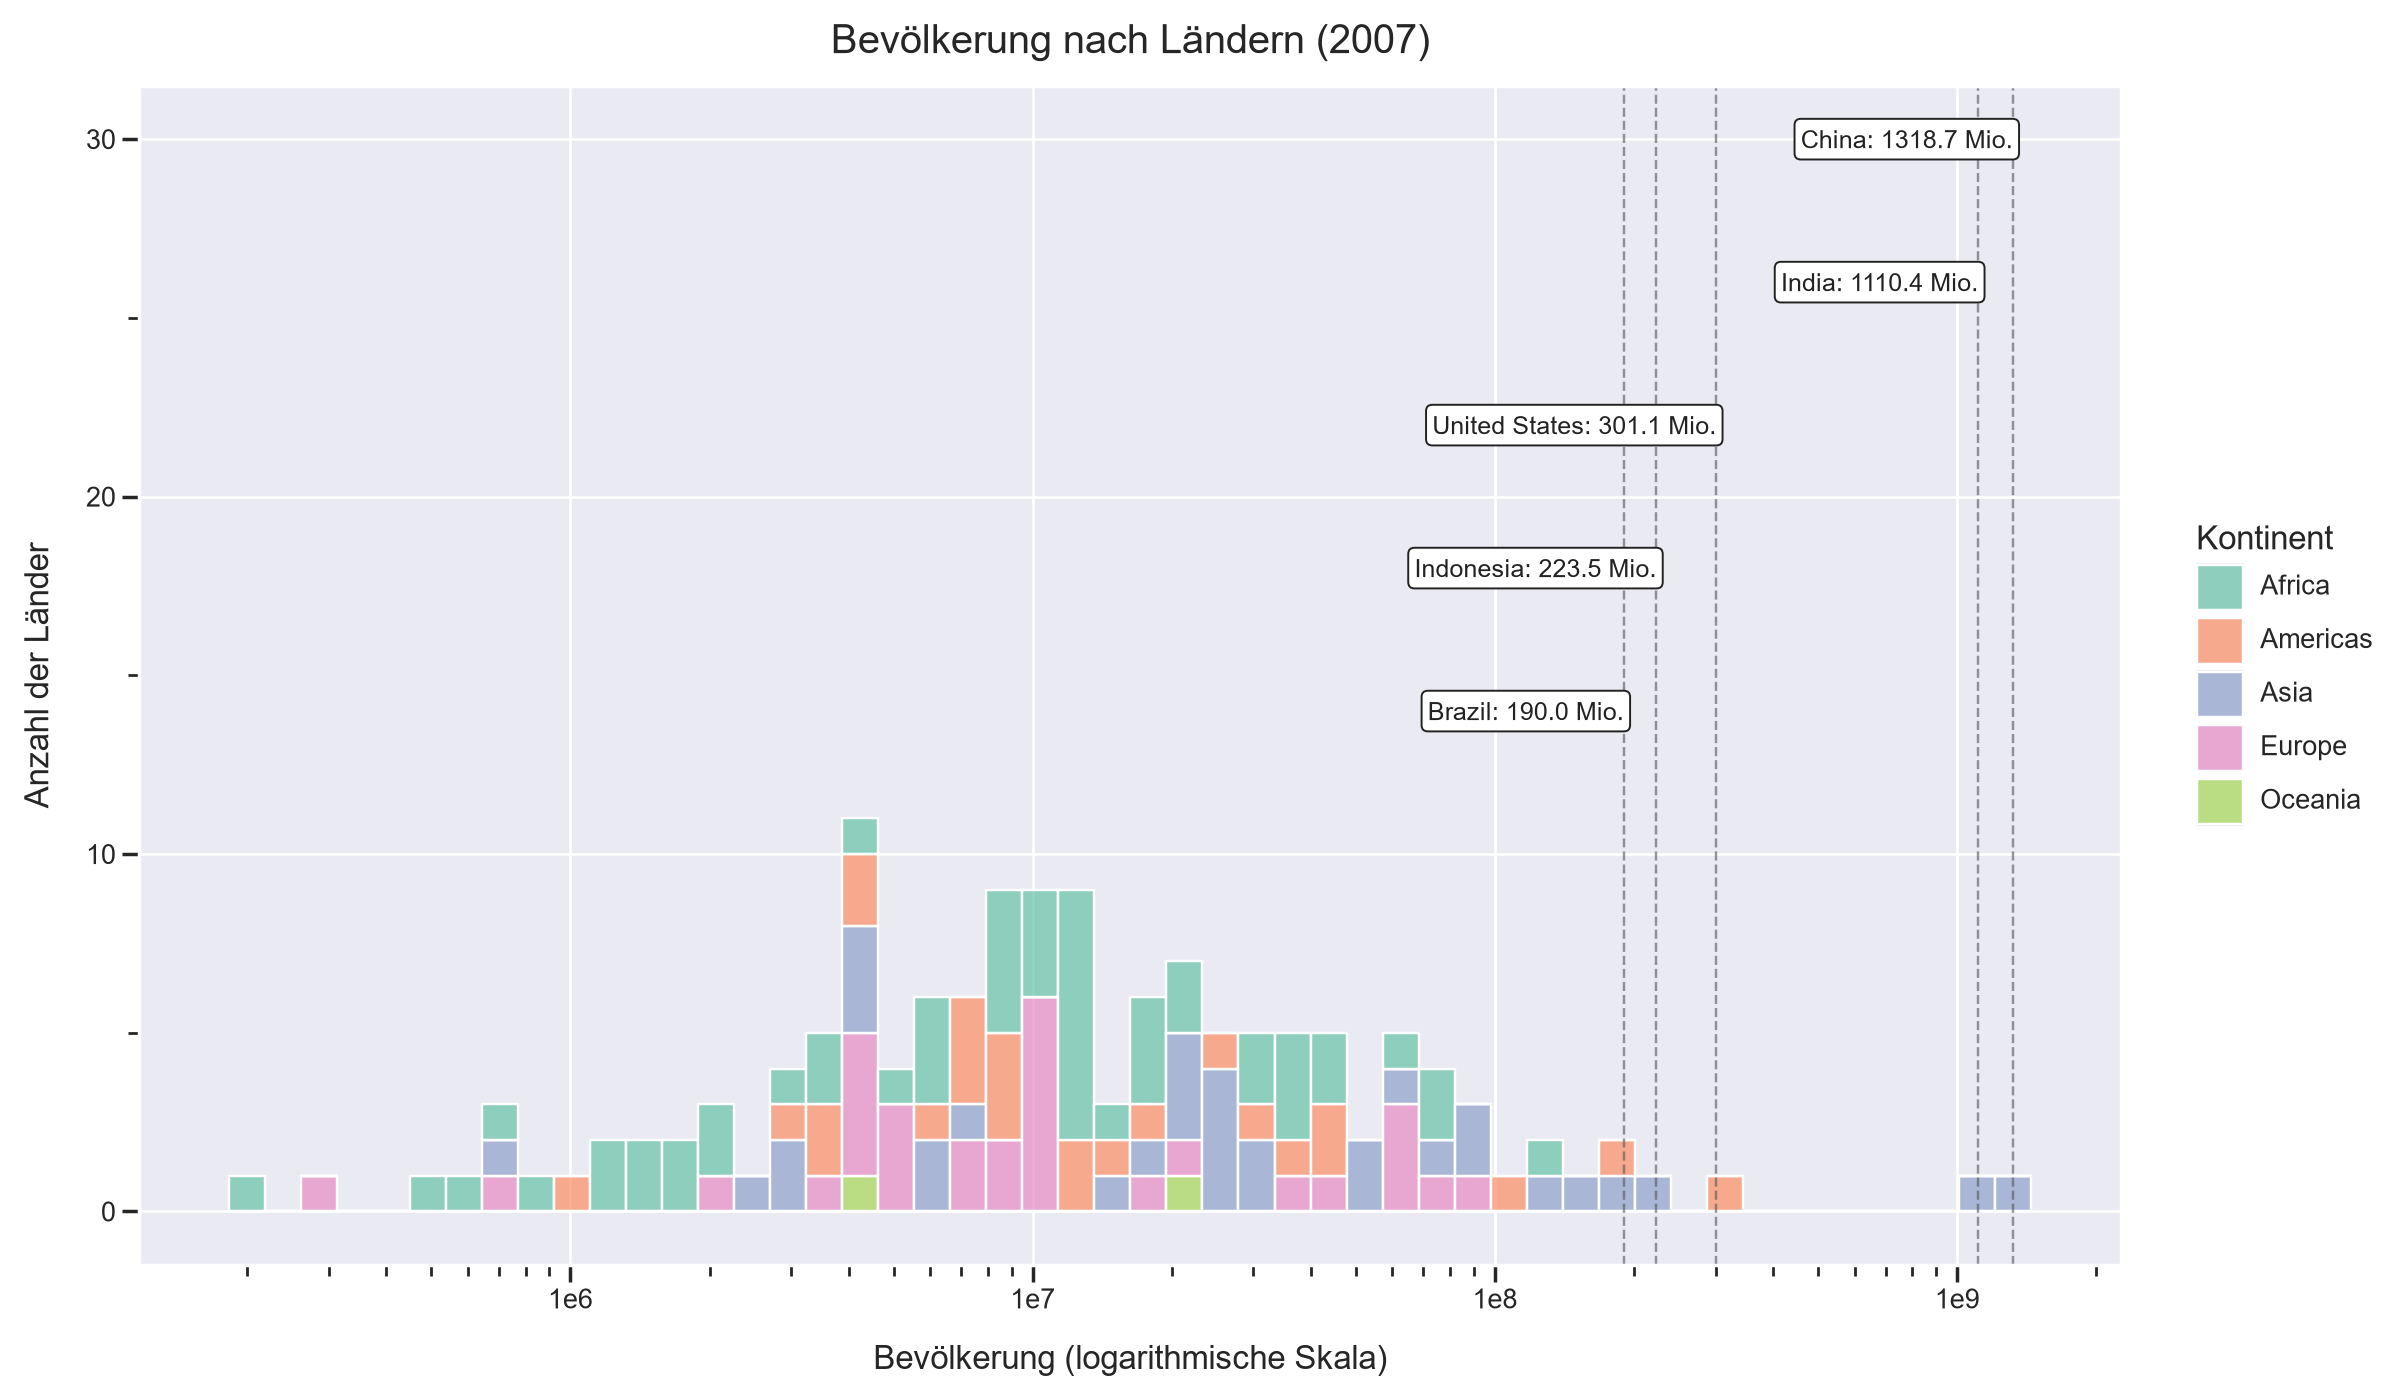

In [53]:
from plotnine import (
    ggplot, aes, geom_histogram, geom_vline, geom_label,
    scale_x_log10, scale_fill_brewer, labs, theme_seaborn, theme
)

data_2007 = gapminder.loc[gapminder["year"] == 2007].copy()

# Die fünf bevölkerungsreichsten Länder
top_5 = data_2007.nlargest(5, "pop").copy()
top_5["label"] = top_5.apply(
    lambda row: f"{row['country']}: {row['pop'] / 1e6:.1f} Mio.",
    axis=1,
)

# Beschriftungen von oben nach unten staffeln
top_5["label_y"] = [30, 26, 22, 18, 14]

plot = (
    ggplot(data_2007, aes(x="pop", fill="continent"))
    + geom_histogram(alpha=0.7, bins=50, color="white")
    + geom_vline(
        data=top_5,
        mapping=aes(xintercept="pop"),
        inherit_aes=False,
        linetype="dashed",
        color="#555555",
        size=0.5,
        alpha=0.6,
    )
    + geom_label(
        data=top_5,
        mapping=aes(x="pop", y="label_y", label="label"),
        inherit_aes=False,
        ha="right",
        size=9,
        fill="white",
        color="#222222",
    )
    + scale_x_log10()
    + scale_fill_brewer(type="qual", palette="Set2")
    + labs(
        title="Bevölkerung nach Ländern (2007)",
        x="Bevölkerung (logarithmische Skala)",
        y="Anzahl der Länder",
        fill="Kontinent",
    )
    + theme_seaborn()
    + theme(figure_size=(12, 7))
)

display(plot)

# Aufgabe 1

Frage: Wie hängen Einkommen und Lebenserwartung zusammen?
Ziel: Verständnis von Aesthetic Mapping und Scale Transformation (lineare und log Skala)

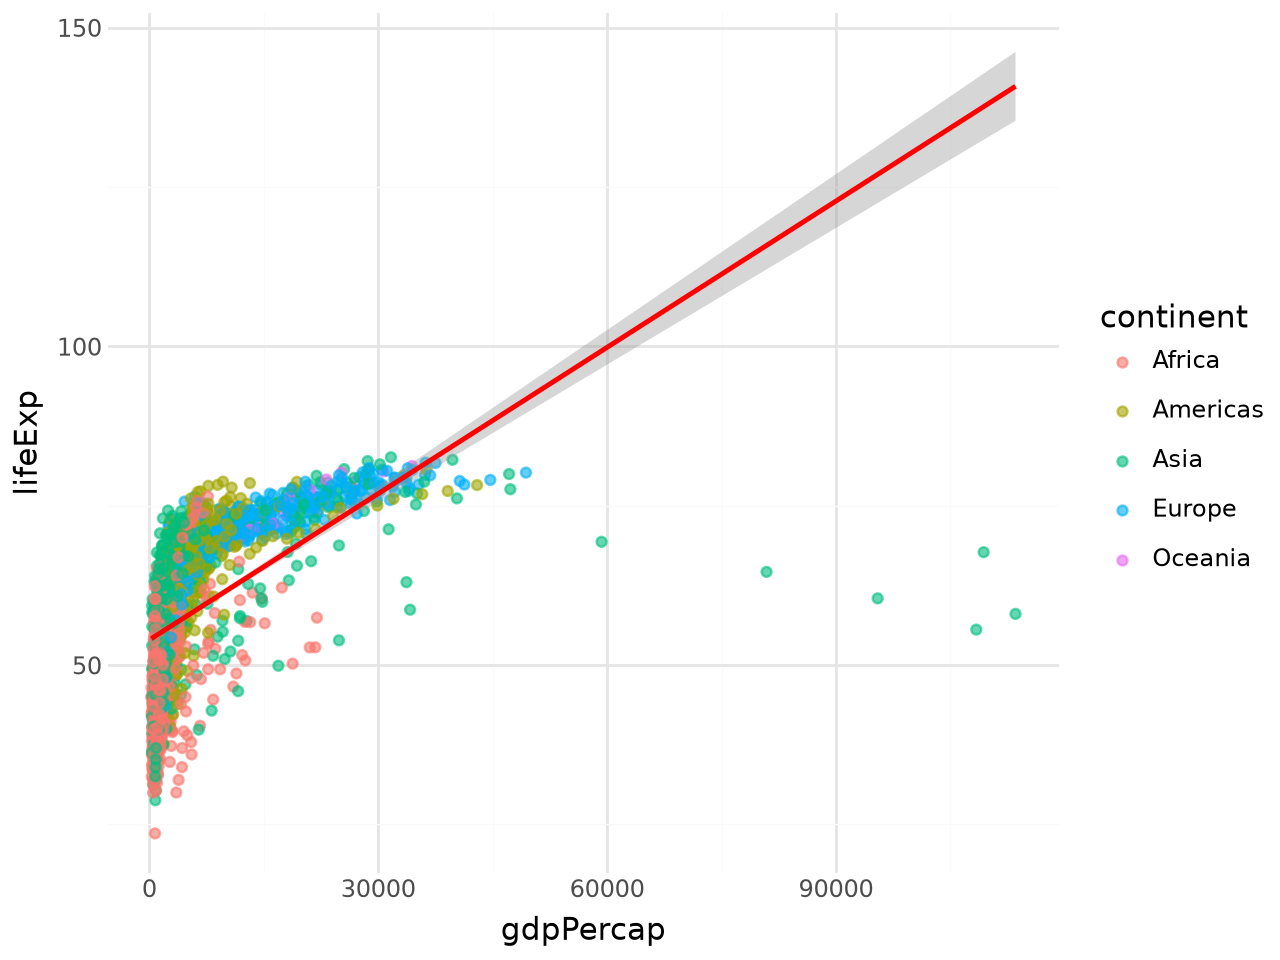

In [54]:
# Lineare Skala (x-Achse)
plot = (
  ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
  + geom_point(alpha= 0.6)
  + theme_minimal()
  + geom_smooth(method='lm', color='red')
)
plot


f:\Uni\Datenvisualisierung2026\.venv\Lib\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_point : Removed 3 rows containing missing values.


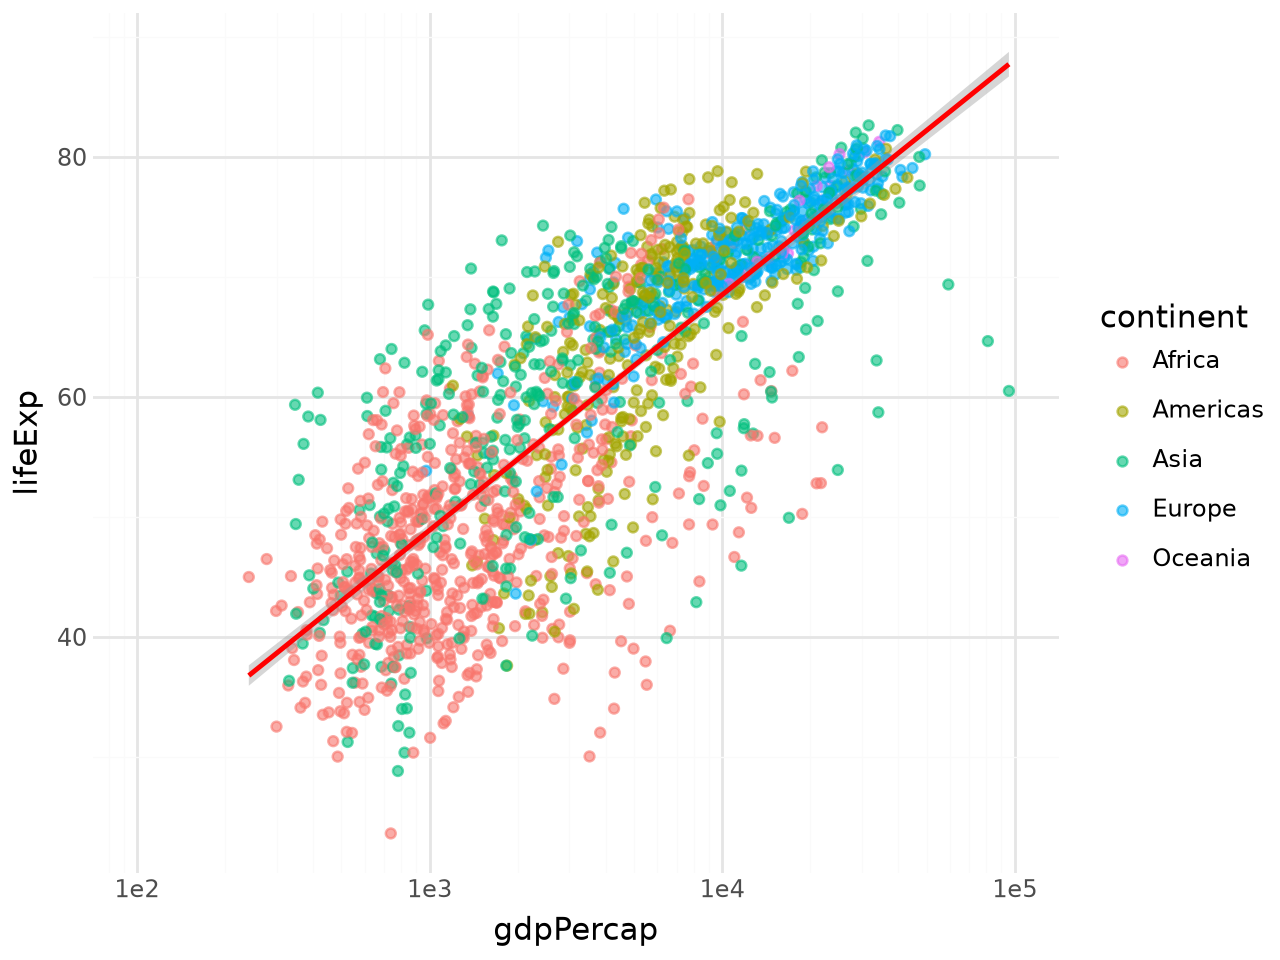

In [55]:
# Logarithmische Skala (x-Achse) mit angepassten Limits und Breaks
plot = (
  ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
  + geom_point(alpha = 0.6)
  + theme_minimal()
  + geom_smooth(method='lm', color='red')
  + scale_x_log10(limits=(100, 100000), breaks=[100, 1000, 10000, 100000])
)
plot

📊 Interpretation: Reiche Länder haben höhere Lebenserwartung; log-Skala macht die Streuung vergleichbar.

🧠 Didaktische Erklärung:

- data: gapminder stellt die Werte bereit.
- aes(): definiert die Mappings (x, y, color).
- geom_point(): legt das Geometrische Objekt fest (Punkte).
- scale_x_log10(): verändert die Skala und damit die Wahrnehmung des Musters.
- theme_minimal(): steuert das Design der Darstellung.

→ Zentrale Idee: Jede Grafik entsteht aus Schichten (Layern), die kombiniert werden.

# Aufgabe 2

Frage: Wie unterscheiden sich die Kontinente in der Lebenserwartung (2007)?

Ziel: Lernen, wie Geoms und Grouping Verteilungen sichtbar machen. Nutze verschiedene Verteilungsplot-Arten.

Recherchiere unter: https://anyplot.ai/plots oder auf einer Seite deiner Wahl

In [56]:
gap_2007 = gapminder[gapminder['year'] == 2007]


f:\Uni\Datenvisualisierung2026\.venv\Lib\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_point : Removed 3 rows containing missing values.


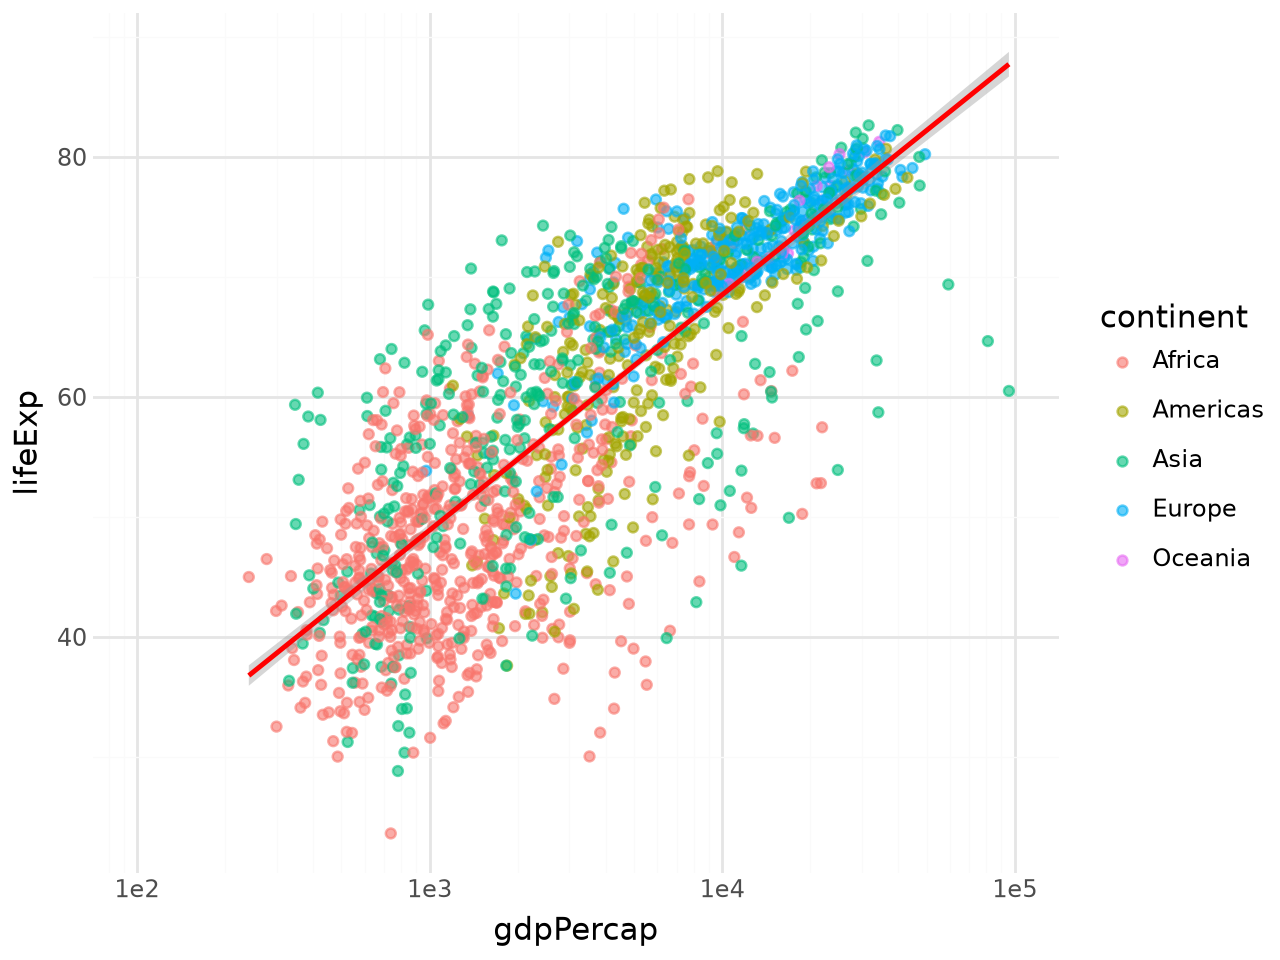

In [59]:
# Plot 2 violin plot (https://plotnine.org/reference/geom_violin.html)

gap_2007 = gapminder[gapminder['year'] == 2007]
sb.violinplot(x='continent', y='lifeExp', data=gap_2007)
plot.show()

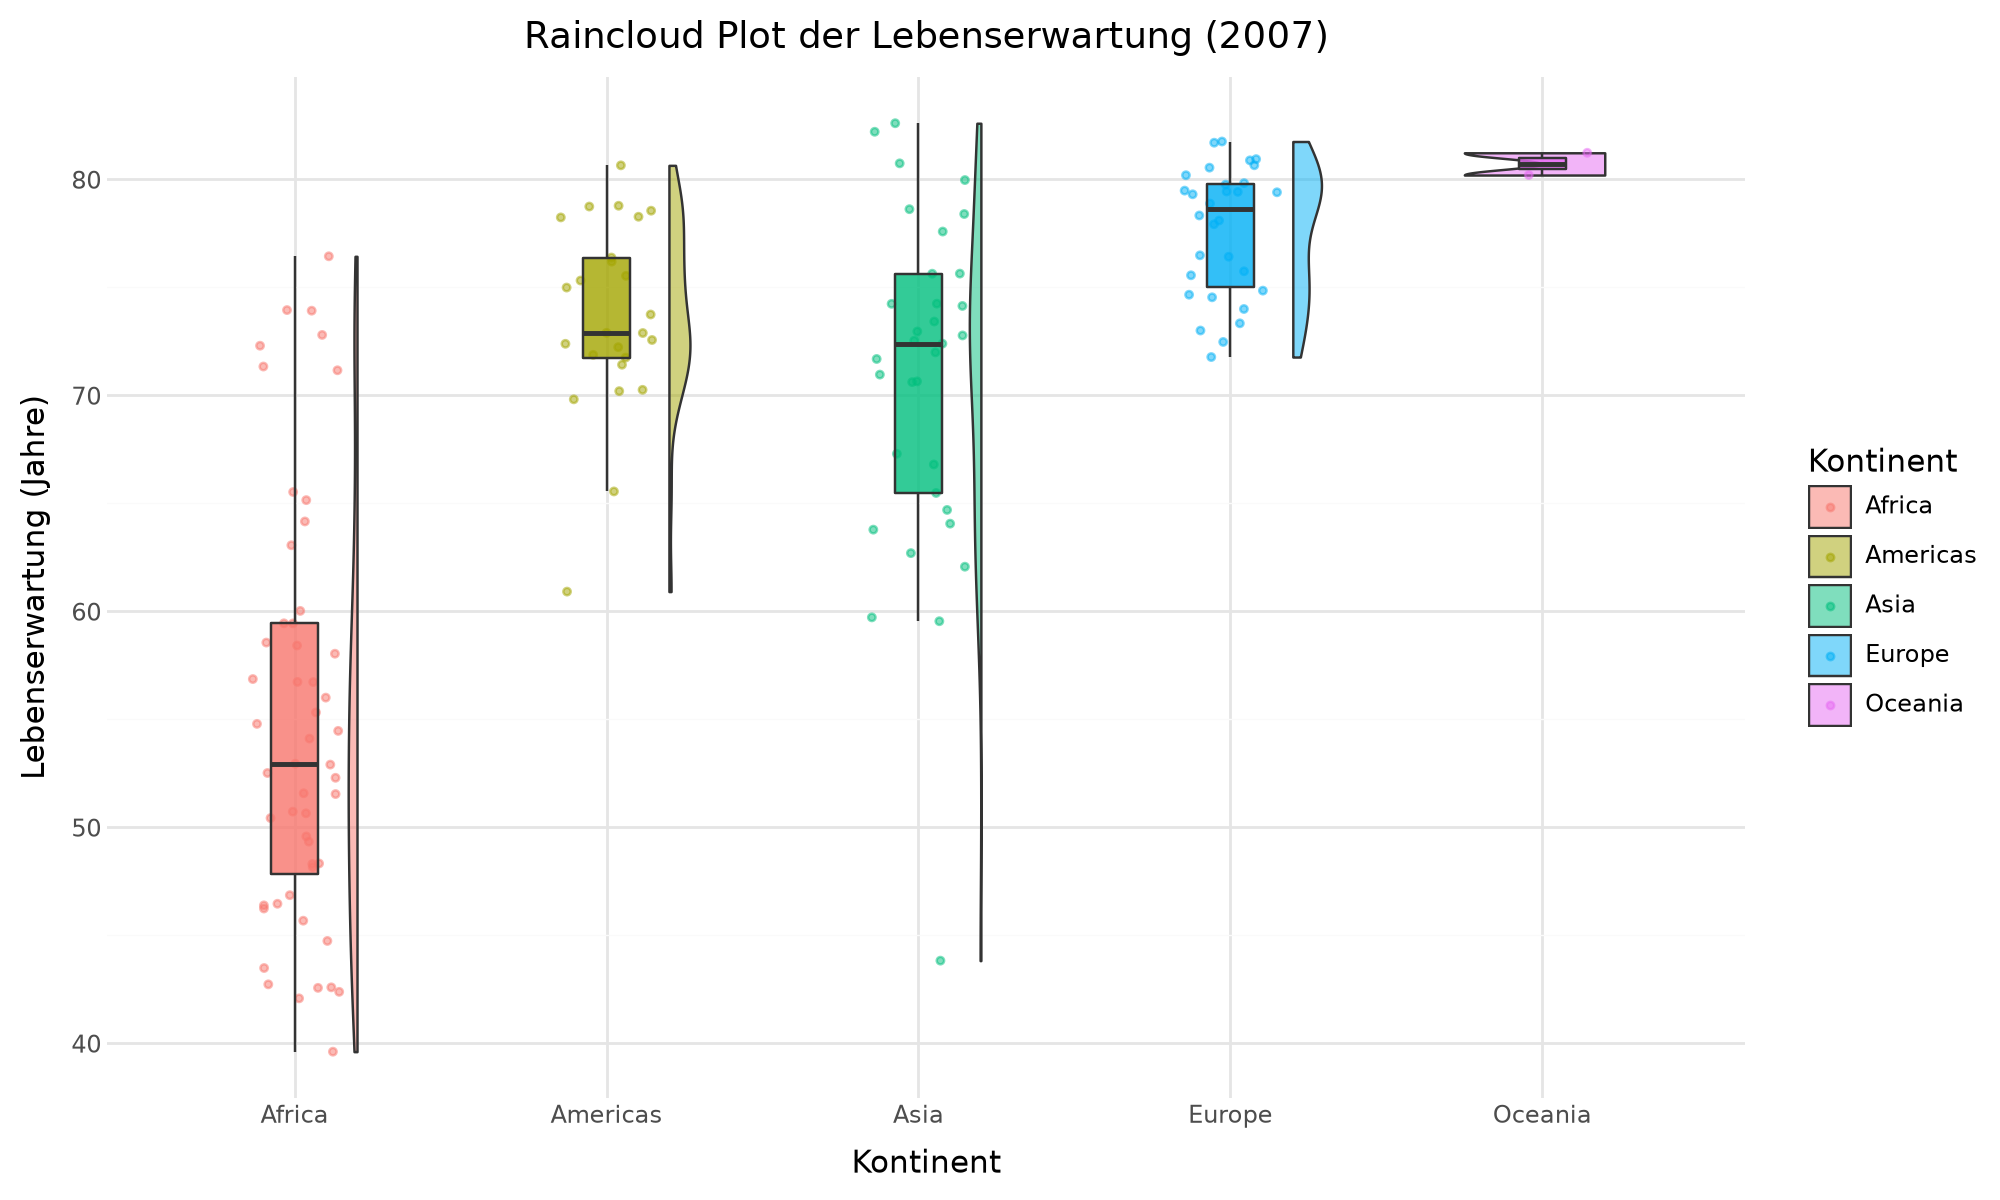

In [60]:
# Plot 3 - "raincloud" plot = boxplot + violinplot (https://r-charts.com/distribution/raincloud-plot/)

from plotnine import (
    ggplot, aes, geom_violin, geom_boxplot, geom_point,
    position_nudge, position_jitter, stage,
    theme_minimal, theme, labs
)
import matplotlib.pyplot as plt

gap_2007 = gapminder[gapminder['year'] == 2007]

# Erstellung eines Raincloud Plots mit plotnine
plot = (
    ggplot(gap_2007, aes(x='continent', y='lifeExp', fill='continent'))
    # 1. Die Wolke (Violinplot nach rechts verschoben)
    + geom_violin(position=position_nudge(x=0.2), alpha=0.5, style='left-right')
    # 2. Der Regen (Datenpunkte nach links verschoben und gestreut)
    + geom_point(aes(color='continent'), position=position_jitter(width=0.15, height=0), size=1, alpha=0.5)
    # 3. Der Boxplot in der Mitte
    + geom_boxplot(width=0.15, outlier_shape='', alpha=0.8, show_legend=False)
    + labs(
        title='Raincloud Plot der Lebenserwartung (2007)',
        x='Kontinent',
        y='Lebenserwartung (Jahre)',
        fill='Kontinent',
        color='Kontinent'
    )
    + theme_minimal()
    + theme(figure_size=(10, 6))
)

plot

📈 Interpretation: Europa und Ozeanien liegen vorn, Afrika mit geringerer Lebenserwartung und größerer Streuung.

🧠 Didaktische Erklärung:
- geom_boxplot(): anderer Geom-Typ = anderer Informationsfokus → Verteilungen statt Einzelpunkte
- fill: Färbung der Flächen, unterscheidet sich von color (Umriss).
- Grammar of Graphics erlaubt, durch Geom-Wechsel völlig neue Fragen zu stellen.

# Aufgabe 3

Frage: Wie hat sich die Lebenserwartung der Länder (nach Kontinenten) über die Zeit verändert?

Ziel: Lernen, wie Facets Teilmengen der Daten trennen und Muster sichtbar machen.

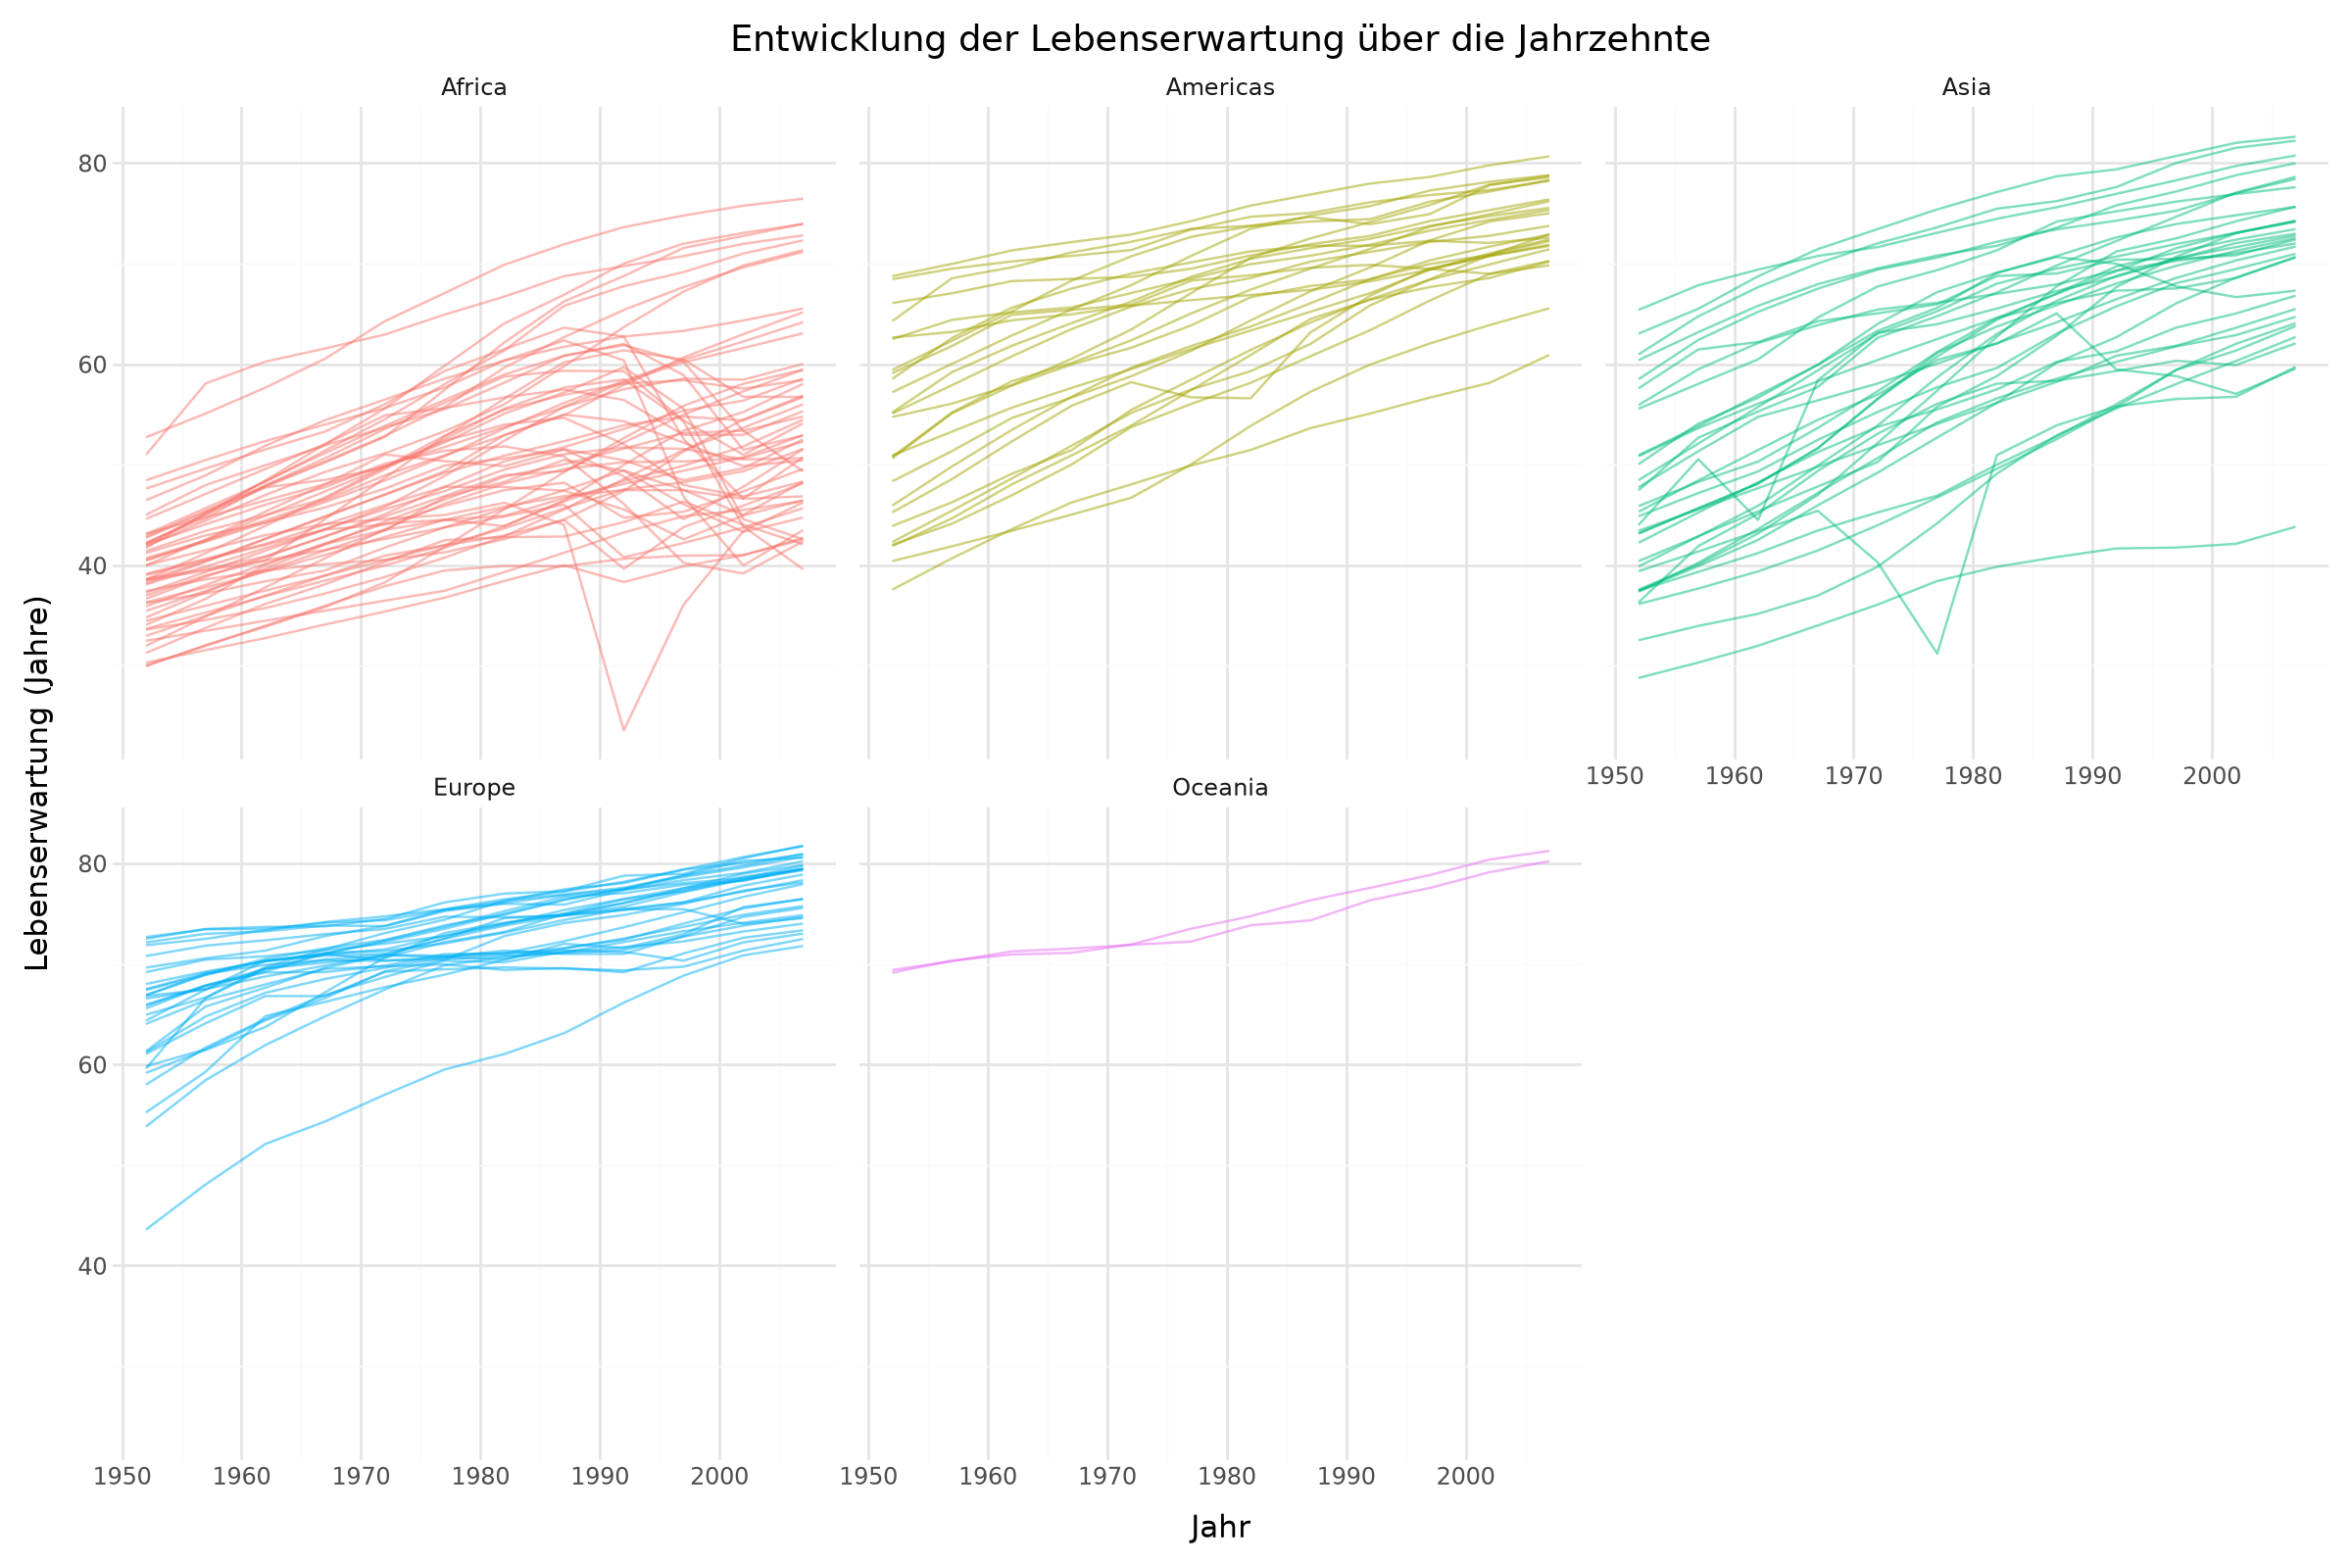

In [61]:
# Liniendiagramm für die Entwicklung der Lebenserwartung über die Zeit nach Kontinenten
plot = (
    ggplot(gapminder, aes(x='year', y='lifeExp', group='country', color='continent'))
    + geom_line(alpha=0.5, show_legend=False)
    + facet_wrap('~continent')
    + labs(
        title='Entwicklung der Lebenserwartung über die Jahrzehnte',
        x='Jahr',
        y='Lebenserwartung (Jahre)'
    )
    + theme_minimal()
    + theme(figure_size=(12, 8))
)
plot

📊 Interpretation: Alle Kontinente zeigen steigende Lebenserwartung, Afrika jedoch auf niedrigerem Niveau.

🧠 Didaktische Erklärung:

- geom_line(): verbindet Werte eines Landes → zeigt Trend.
- group: legt fest, dass Linien pro Land gezogen werden.
- facet_wrap(): unterteilt die Grafik nach Kategorien → mehrere kleine Diagramme mit gleichem Mapping.
- Facets = strukturierte Mehrfachdarstellungen — zeigen Vergleichbarkeit über Gruppen.

##### Frage: Was kann an dieser Visualisierung verbessert werden? Wie wäre es mit der Hervorhebung von ausgewählten Ländern in den Kontinenten?

In [62]:
# Liste der hervorzuhebenden Länder und Ländercode-Mapping
highlight_countries = ['Germany', 'France', 'Japan', 'United States', 'Nigeria', 'India', "Australia", "Brazil", "China", "South Africa"]
country_codes = {'Germany': 'DE', 'France': 'FR', 'Japan': 'JP', 'United States': 'US', 'Nigeria': 'NG', 'India': 'IN', 'Australia': 'AU', 'Brazil': 'BR', 'China': 'CN', 'South Africa': 'ZA'}

highlight_data = gapminder[gapminder['country'].isin(highlight_countries)].copy()
highlight_2007 = highlight_data[highlight_data['year'] == 2007].copy()

# Neue Spalte mit Country-Codes
highlight_2007['code'] = highlight_2007['country'].map(country_codes)


# Aufgabe 4

Frage: Wie verändern sich die globalen Muster von Wohlstand und Lebenserwartung über die Jahrzehnte hinweg? Sind die Unterschiede zwischen Kontinenten konstant, oder nähern sich Länder im Laufe der Zeit an?

Ziel: Verstehen, wie Änderungen von Zusammenhängen im Zeitverlauf visualisiert werden können – und wie man mit Facets mehrere Zeitabschnitte gleichzeitig visualisieren kann.

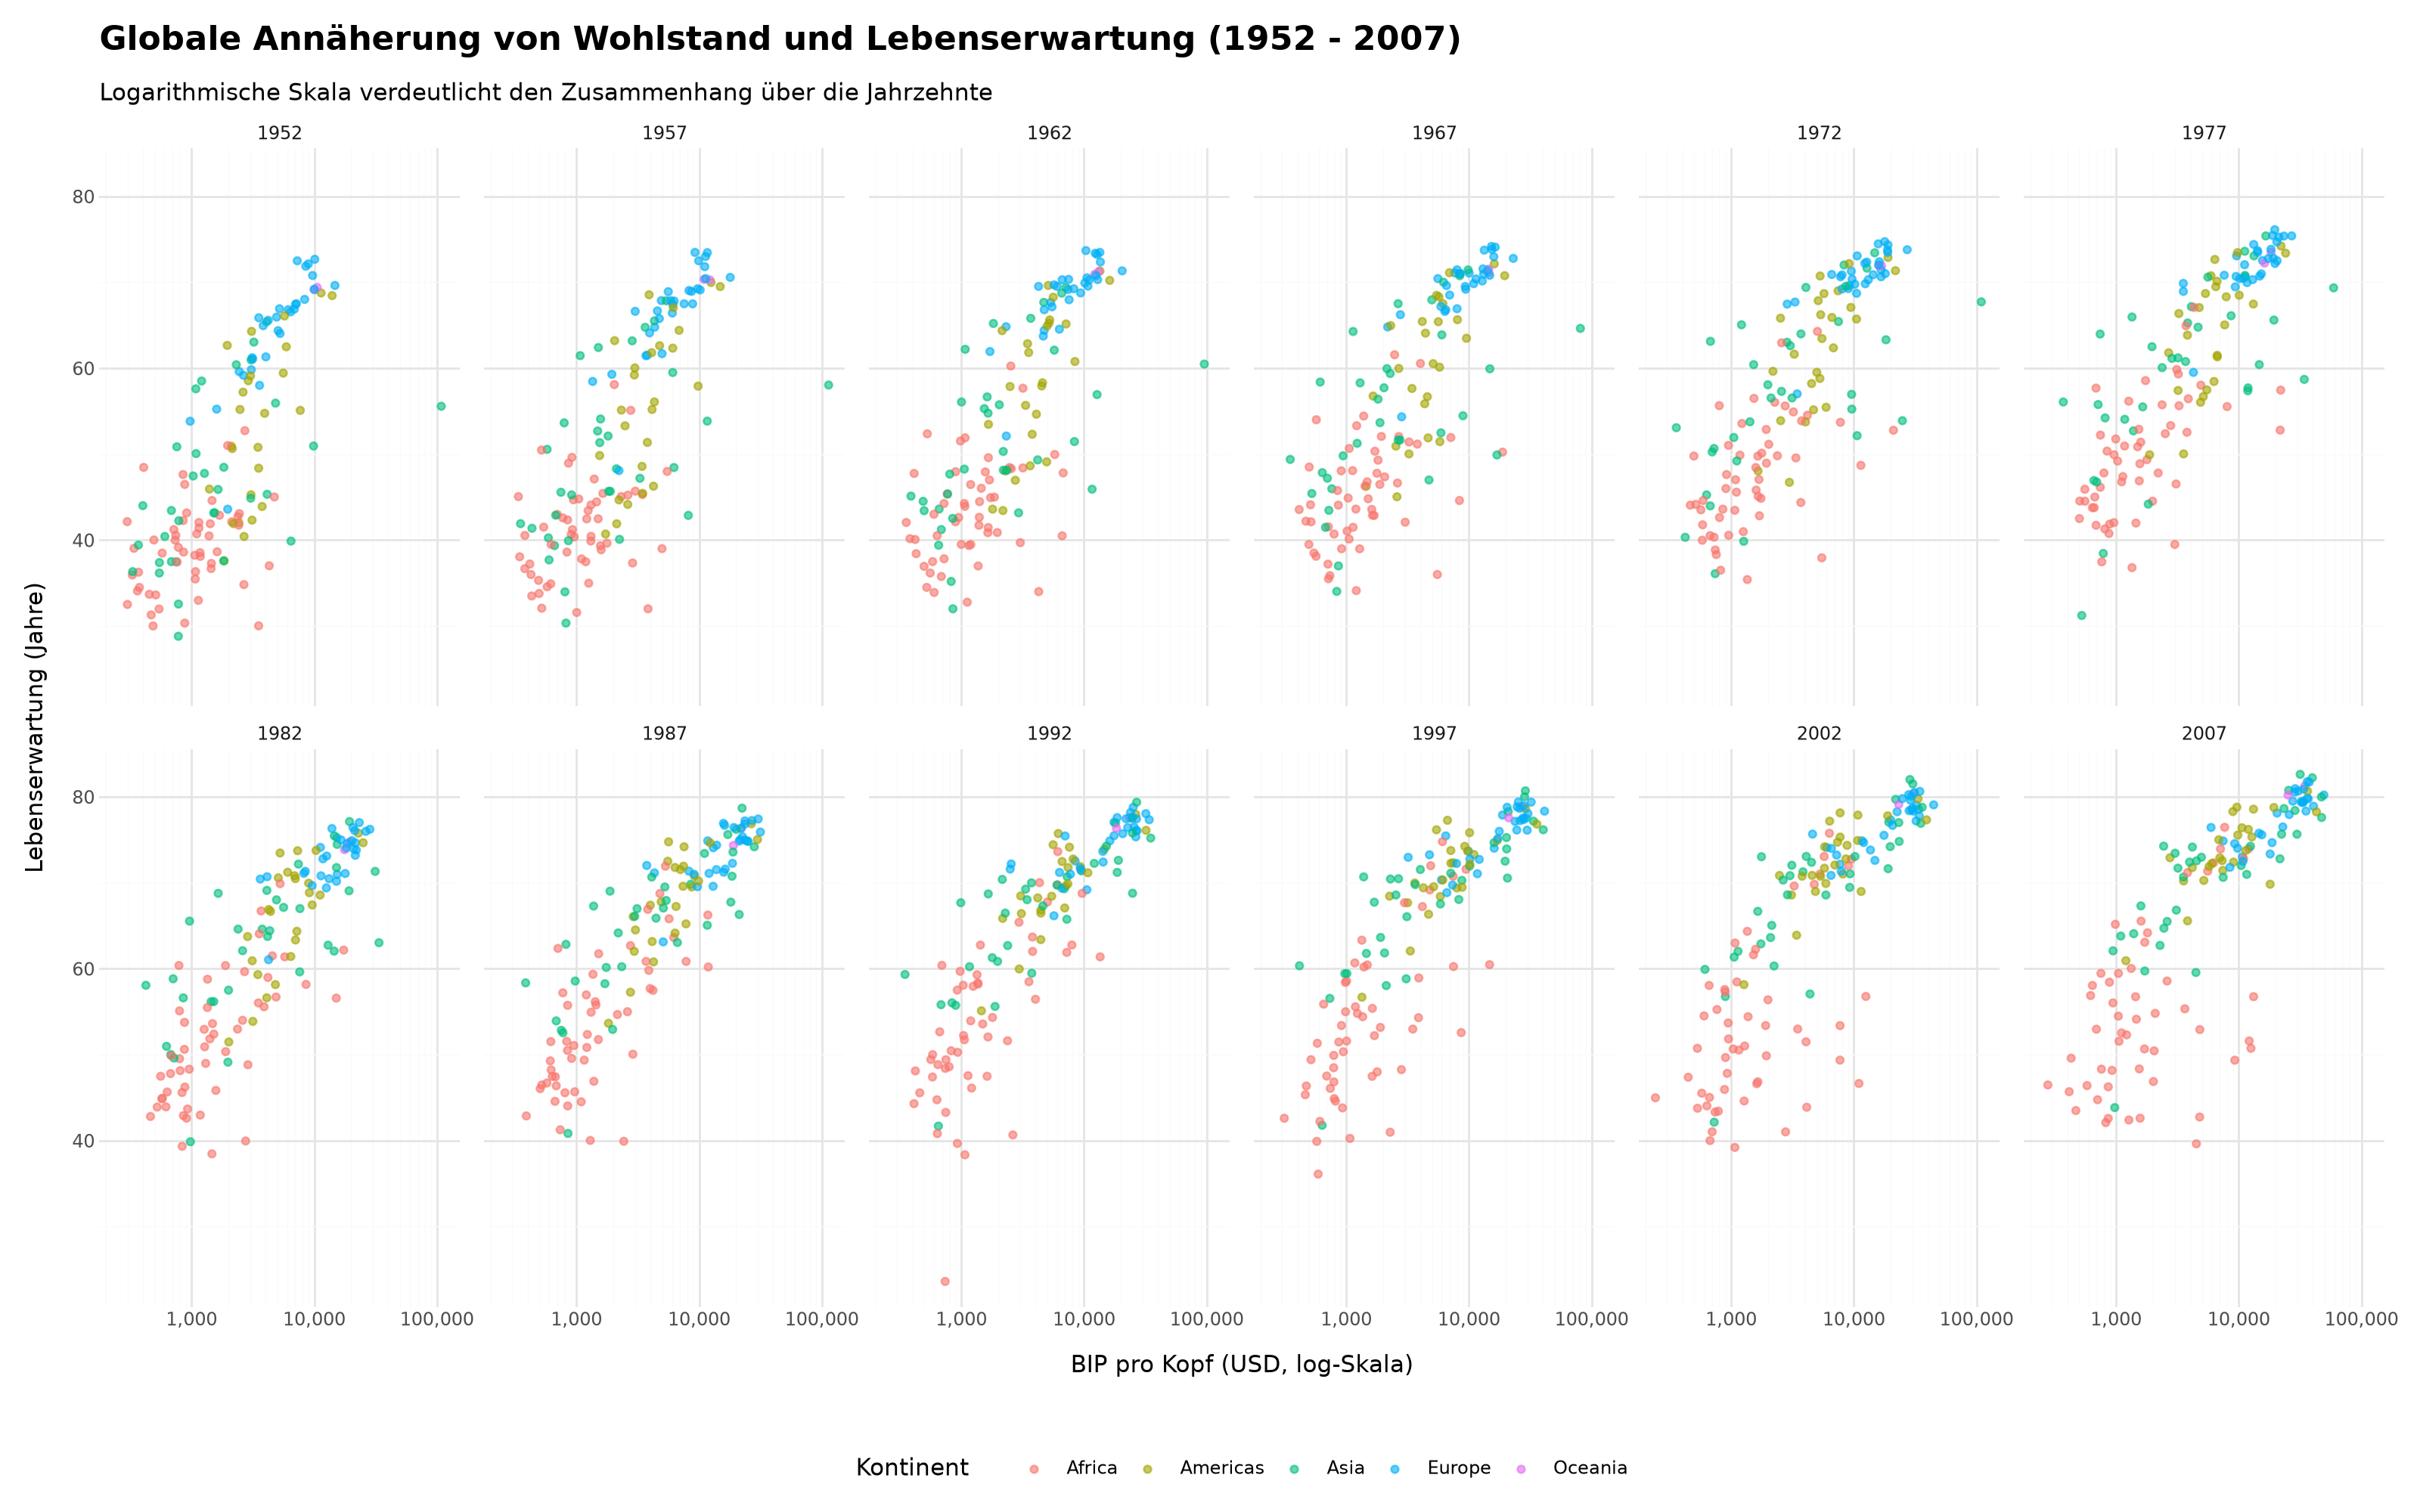

In [63]:
# Aufgabe 4: Globale Entwicklung von Wohlstand und Lebenserwartung über die Jahrzehnte
plot = (
    ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
    + geom_point(alpha=0.6)
    + scale_x_log10(labels=lambda l: [f"{int(x):,}" for x in l])
    + facet_wrap('~year', nrow=2)
    + labs(
        title='Globale Annäherung von Wohlstand und Lebenserwartung (1952 - 2007)',
        subtitle='Logarithmische Skala verdeutlicht den Zusammenhang über die Jahrzehnte',
        x='BIP pro Kopf (USD, log-Skala)',
        y='Lebenserwartung (Jahre)',
        color='Kontinent'
    )
    + theme_minimal()
    + theme(
        figure_size=(16, 10),
        legend_position='bottom',
        plot_title=element_text(weight='bold', size=16)
    )
)
plot

📊 Interpretation der Ergebnisse
- Mit zunehmenden Jahren verschieben sich die Punkte nach rechts oben → Länder werden reicher und älter.
- Die Cluster der Kontinente wandern näher zusammen → globale Annäherung in Lebenserwartung.
- Afrika bleibt mit geringem Einkommen und niedriger Lebenserwartung zurück, zeigt aber Zuwächse.
- Faceting erlaubt eine visuelle Zeitreise durch Jahrzehnte — dieselben Mappings, aber verschiedene Teilmengen.

🧠 Didaktische Erklärung:
- `data`: legt die Datenquelle fest → Was wird gezeigt? → Beispiel: gapminder
- `aes()`: definiert das Mapping → Wie werden Daten visuell kodiert? → x = gdpPercap, y = lifeExp, color = continent
- `geom_point()`: bestimmt die Darstellungsform → Was wird gezeichnet? → Punkte für Länder im Streudiagramm
- `scale_x_log10()`: verändert die Skala → Wie wird der Wertebereich abgebildet? → Logarithmische Darstellung für bessere Vergleichbarkeit
- `facet_wrap('~year')`: teilt nach Gruppen → Wie werden Teilmengen gezeigt? → Ein Plot pro Jahr zur Zeitreihenanalyse
- `labs()`: ergänzt Kontext → Wie wird erklärt, was gezeigt wird? → Titel, Achsen, Legende
- `alpha = 0.6`: steuert Sichtbarkeit → Wie klar ist das Bild? → leichte Transparenz gegen Überlagerung

- Facets sind keine neue Art von Plot, sondern eine systematische Anwendung der gleichen Grammatik auf Teilmengen der Daten.
- Der Code zeigt, dass das “Baukastenprinzip” der Grammar of Graphics erweiterbar ist:
→ `data + aes + geom + scale + facet + theme + labels`
Besonders geeignet zur Demonstration des Konzepts „same grammar – multiple stories“.


# 5 Bonus: Themes

Erstelle ein Liniendiagramm mit der Entwicklung Lebenserwartung für die 5 größten Europäischen Länder und nutze unterschiedliche Themes.  

### plotnine

Vorlage: https://plotnine.org/guide/themes-premade.html

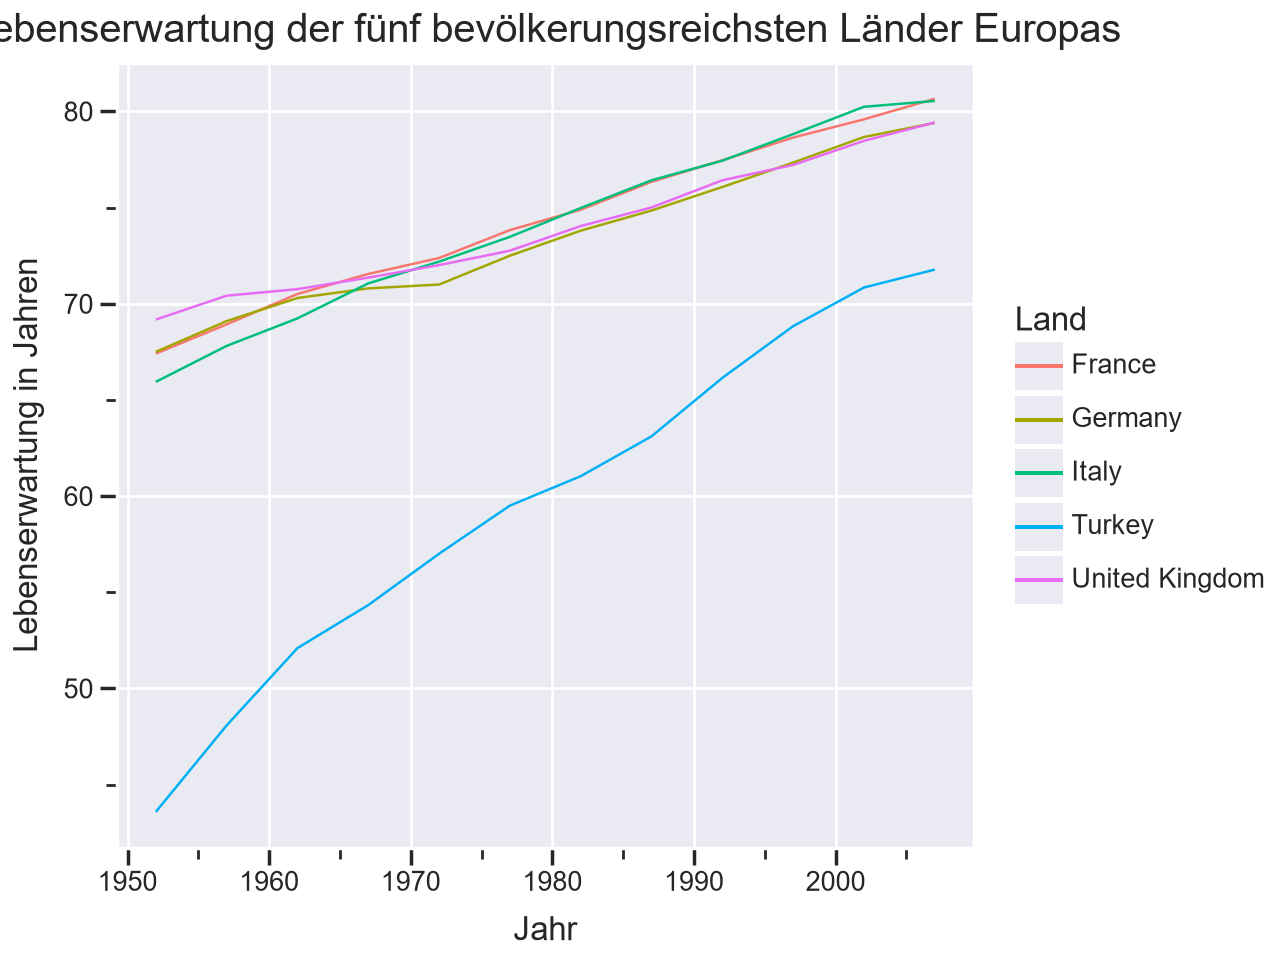

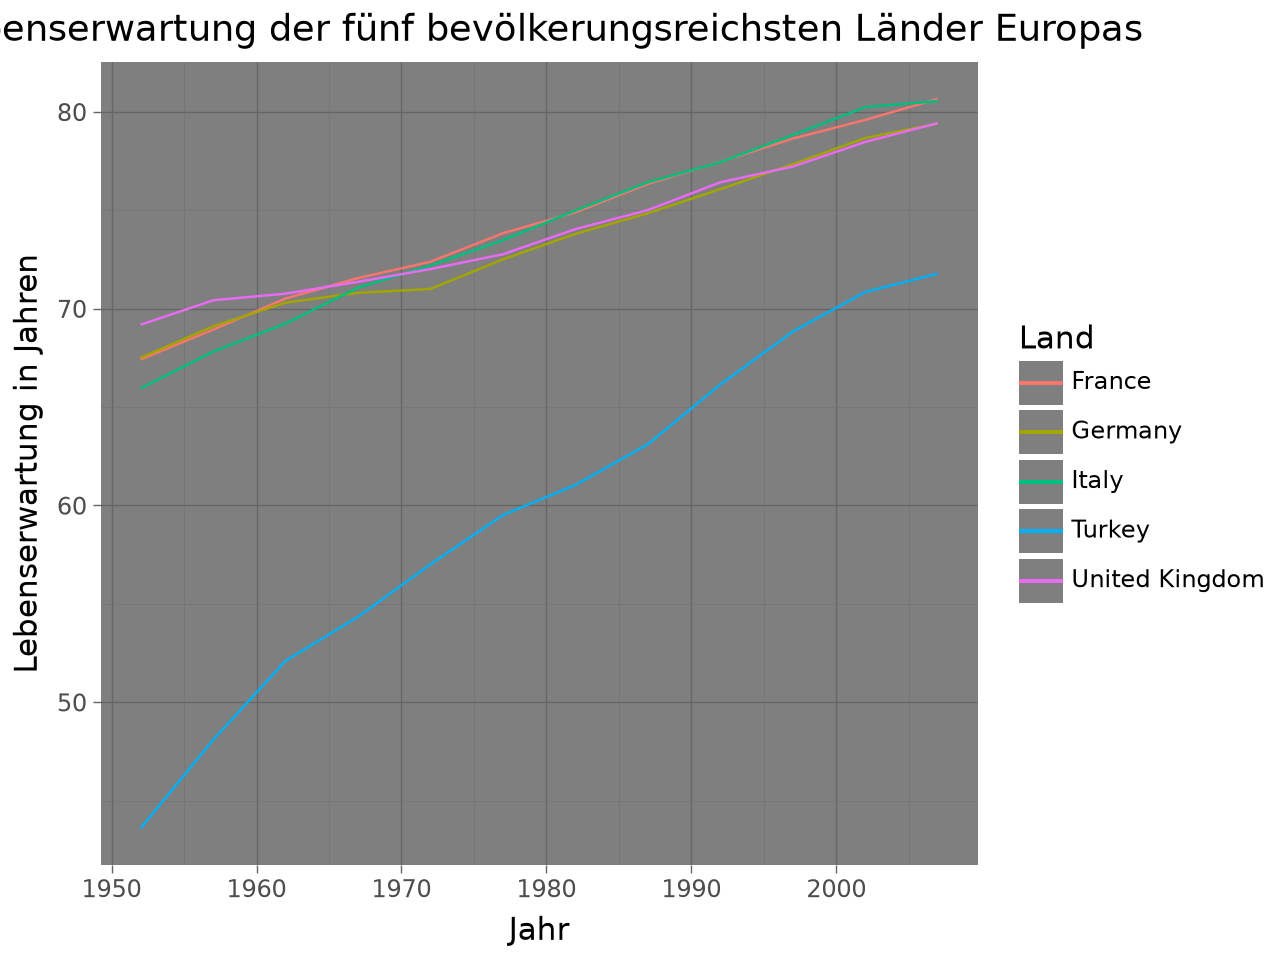

In [68]:
# Groesste Laender: hoechste Bevoelkerung im letzten Jahr des Gapminder-Datensatzes (2007)
europe_2007 = gapminder.query("continent == 'Europe' and year == 2007")
top_5_european_countries = europe_2007.nlargest(5, "pop")["country"].tolist()
top_5_europe = gapminder[gapminder["country"].isin(top_5_european_countries)].copy()
diagramm = (
    ggplot(top_5_europe, aes(x="year", y="lifeExp", color="country"))
    + geom_line()
    + labs(
        title="Lebenserwartung der fünf bevölkerungsreichsten Länder Europas",
        x="Jahr",
        y="Lebenserwartung in Jahren",
        color="Land"
    )
)

display(diagramm + theme_seaborn())
display(diagramm + theme_dark())


### Economist Style (als matplotlib chart)

Vorlage: https://deepnote.com/app/radovankavicky/2022-07-01-Making-Economist-Style-Plots-in-Matplotlib-84f9c86d-1559-4654-b226-3dcff8be3408

``` # Setup plot size.
fig, ax = plt.subplots(figsize=(8,4))

# Create grid
# Zorder tells it which layer to put it on. We are setting this to 1 and our data to 2 so the grid is behind the data.
ax.grid(which="major", axis='y', color='#758D99', alpha=0.6, zorder=1)

# Plot data
# Loop through country names and plot each one.
for country in countries:
    ax.plot(gdp[gdp['country'] == country]['date'],
            gdp[gdp['country'] == country]['gdp_trillions'],
            color='#758D99',
            alpha=0.8,
            linewidth=3)

# Plot US and China separately
ax.plot(gdp[gdp['country'] == 'United States']['date'],
        gdp[gdp['country'] == 'United States']['gdp_trillions'],
        color='#006BA2',
        linewidth=3)

ax.plot(gdp[gdp['country'] == 'China']['date'],
        gdp[gdp['country'] == 'China']['gdp_trillions'],
        color='#3EBCD2',
        linewidth=3)

# Remove splines. Can be done one at a time or can slice with a list.
ax.spines[['top','right','left']].set_visible(False)

# Shrink y-lim to make plot a bit tigheter
ax.set_ylim(0, 23)

# Set xlim to fit data without going over plot area
ax.set_xlim(pd.datetime(1958, 1, 1), pd.datetime(2023, 1, 1))

# Reformat x-axis tick labels
ax.xaxis.set_tick_params(labelsize=11)        # Set tick label size

# Reformat y-axis tick labels
ax.set_yticklabels(np.arange(0,25,5),            # Set labels again
                   ha = 'right',                 # Set horizontal alignment to right
                   verticalalignment='bottom')   # Set vertical alignment to make labels on top of gridline      

ax.yaxis.set_tick_params(pad=-2,             # Pad tick labels so they don't go over y-axis
                         labeltop=True,      # Put x-axis labels on top
                         labelbottom=False,  # Set no x-axis labels on bottom
                         bottom=False,       # Set no ticks on bottom
                         labelsize=11)       # Set tick label size

# Add labels for USA and China
ax.text(x=.63, y=.67, s='United States', transform=fig.transFigure, size=10, alpha=.9)
ax.text(x=.7, y=.4, s='China', transform=fig.transFigure, size=10, alpha=.9)


# Add in line and tag
ax.plot([0.12, .9],                  # Set width of line
        [.98, .98],                  # Set height of line
        transform=fig.transFigure,   # Set location relative to plot
        clip_on=False,
        color='#E3120B',
        linewidth=.6)
ax.add_patch(plt.Rectangle((0.12,.98),                 # Set location of rectangle by lower left corder
                           0.04,                       # Width of rectangle
                           -0.02,                      # Height of rectangle. Negative so it goes down.
                           facecolor='#E3120B',
                           transform=fig.transFigure,
                           clip_on=False,
                           linewidth = 0))

# Add in title and subtitle
ax.text(x=0.12, y=.91, s="Ahead of the pack", transform=fig.transFigure, ha='left', fontsize=13, weight='bold', alpha=.8)
ax.text(x=0.12, y=.86, s="Top 9 GDP's by country, in trillions of USD, 1960-2020", transform=fig.transFigure, ha='left', fontsize=11, alpha=.8)

# Set source text
ax.text(x=0.12, y=0.01, s="""Source: "GDP of all countries(1960-2020)" via Kaggle.com""", transform=fig.transFigure, ha='left', fontsize=9, alpha=.7)

# Export plot as high resolution PNG
plt.savefig('images/economist_line.png',    # Set path and filename
            dpi = 300,                     # Set dots per inch
            bbox_inches="tight",           # Remove extra whitespace around plot
            facecolor='white')             # Set background color to white
```

# Bonus: Weitere Gapminder Indikatoren

Durchsucht die [Gapminder Plattform](https://www.gapminder.org/data/) nach weiteren Indikatoren und visualisiert diese.

Z.B. Wieviele Kinder werden je Frau geboren, wieviele Verkehrstote gibt es nach Ländern ...

Viel Spaß beim Visualisieren!
